In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F
import numpy as np
import re
import matplotlib.pyplot as plt
from collections import Counter


In [2]:
# Do we have CUDA? If the answer is cpu this will be painfully slow.
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Training on: {device}")

Training on: cuda


In [3]:
def parse_sta_complete(filepath):
    """
    Correct parser for STA1 2.0.
    Returns flat tokens with '.' as word separator.
    """
    tokens = []
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            
            # Skip headers and empty lines
            if not line or line.startswith('#'):
                continue
            
            # Skip folio metadata lines <fXXx> <! ...>
            if re.match(r'^<[^>]+>\s*<!', line):
                continue
            
            # Extract glyph text (after the position tag)
            match = re.match(r'^<[^>]+>\s+(.*)', line)
            if not match:
                continue
            
            text = match.group(1).strip()
            
            # Clean internal tags and comments
            text = re.sub(r'\{[^}]*\}', '', text)
            text = re.sub(r'<[^>]*>',   '', text)
            text = re.sub(r'-',          '.', text)
            text = text.strip()
            
            if not text:
                continue
            
            # Parse words separated by '.'
            for word_raw in text.split('.'):
                word_raw = word_raw.strip()
                if not word_raw:
                    continue
                
                # Extract 2-character glyphs: Uppercase + digit/lowercase
                glyphs = re.findall(r'[A-Z][0-9a-z]', word_raw)
                
                if glyphs:
                    tokens.extend(glyphs)
                    tokens.append('.')   # word separator
    
    return tokens


# ── Load corpus ────────────────────────────────────────────────────
FILEPATH = 'corpus/voynich_sta.txt'   # ← adjust

raw_tokens = parse_sta_complete(FILEPATH)

# Verification
n_glyphs = sum(1 for t in raw_tokens if t != '.')
n_words = raw_tokens.count('.')
vocab_raw = set(raw_tokens)

print(f"Total tokens (with separators): {len(raw_tokens):,}")
print(f"Total glyphs:                   {n_glyphs:,}")
print(f"Total words:                    {n_words:,}")
print(f"Unique vocabulary:              {len(vocab_raw)}")
print(f"\nFirst 40 tokens:")
print(raw_tokens[:40])

Total tokens (with separators): 194,341
Total glyphs:                   157,254
Total words:                    37,087
Unique vocabulary:              167

First 40 tokens:
['P2', 'A3', 'K1', 'A2', 'C2', '.', 'A2', 'Q1', 'A3', 'B2', '.', 'A3', 'C1', '.', 'Aa', 'Q2', 'A3', 'G1', '.', 'L1', 'A1', 'B2', '.', 'L1', 'A1', 'C1', 'A2', '.', 'U5', 'C2', 'J1', 'C2', '.', 'A2', '.', 'Q1', 'A1', 'C1', '.', 'L1']


Total words/blocks: 37087
Mean length: 4.2 glyphs
Max length: 17 | min: 1

Length distribution:
  1 glyphs: (883)
  2 glyphs: (3529)
  3 glyphs: (8143)
  4 glyphs: (9328)
  5 glyphs: (8269)
  6 glyphs: (4342)
  7 glyphs: (1605)
  8 glyphs: (516)
  9 glyphs: (222)
  10 glyphs: (113)
  11 glyphs: (55)
  12 glyphs: (41)
  13 glyphs: (14)
  14 glyphs: (10)
  15 glyphs: (9)
  16 glyphs: (6)
  17 glyphs: (2)

=== POSITIONAL DISTRIBUTION ===
Glyph      Start%  Middle%     End%    n_words Inferred function
──────────────────────────────────────────────────────────────────────
D1          98.9%     1.0%     0.0%       5420   ✦ PREFIX/IMPERATIVE
A1          44.4%    48.2%     7.4%      21417   ? FREE
B2          15.9%    29.9%    54.2%       9998   ? FREE
K1          57.0%    40.8%     2.3%      10609   ? FREE
Q1          18.2%    80.3%     1.6%       9798   ● ROOT/NOUN
P2          41.4%    52.2%     6.4%        423   ? FREE
V1           8.3%    83.3%     8.3%         12   ● ROOT/NOUN
T1        

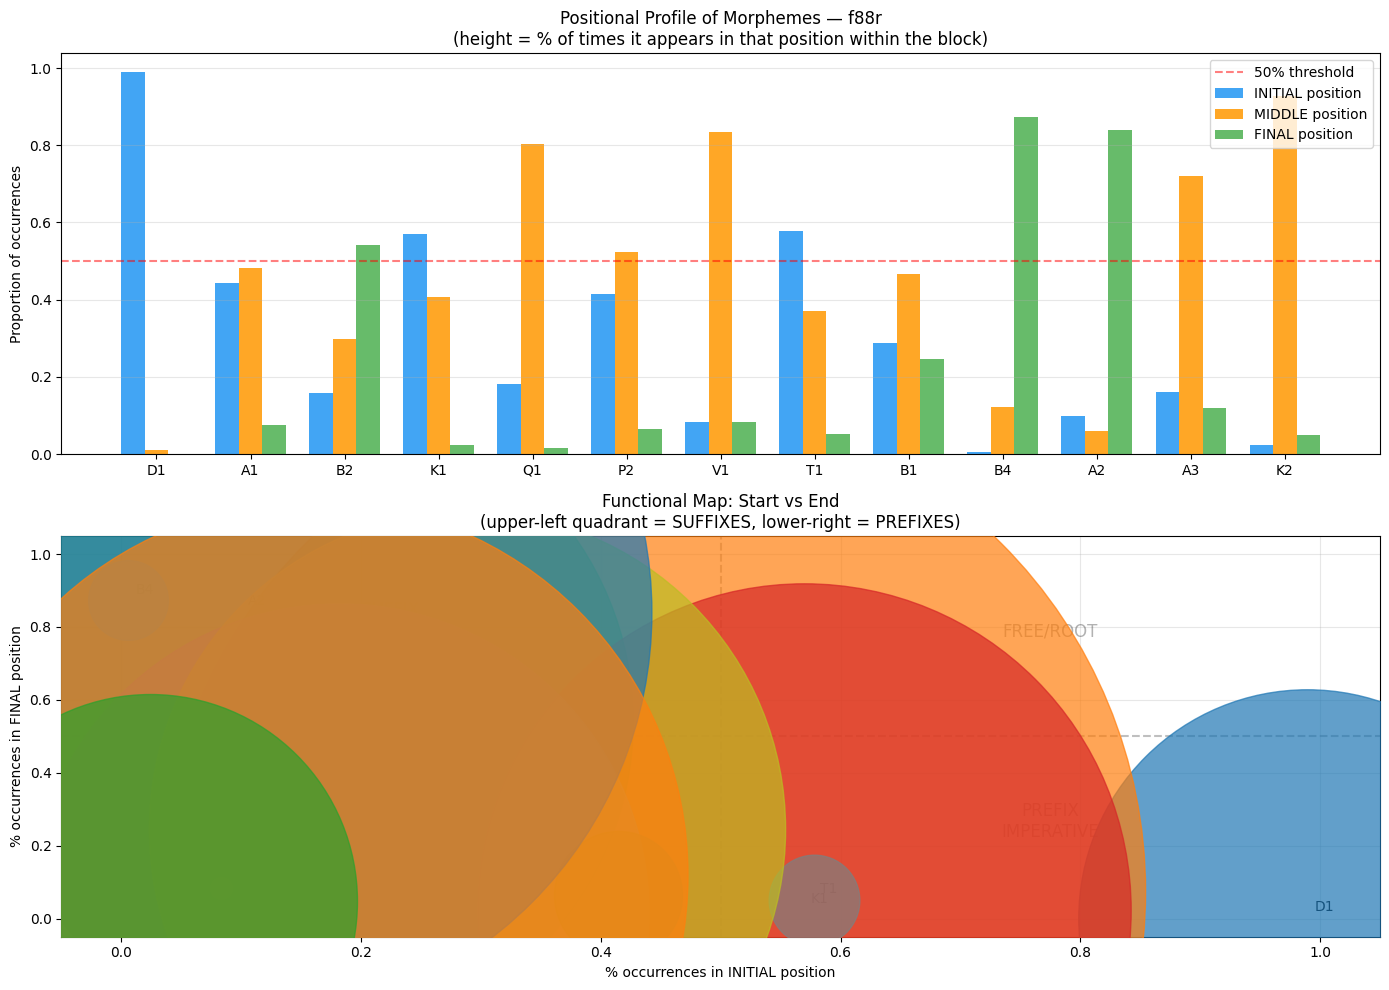

In [4]:
def positional_morpheme_analysis_v2(raw_tokens, morphemes_of_interest=None):
    """
    Corrected version: handles single-glyph words.
    """
    if morphemes_of_interest is None:
        # Include those from our hypotheses + PPMI ones
        morphemes_of_interest = ['D1', 'A1', 'B2', 'K1', 'Q1', 'P2', 
                           'V1', 'T1', 'B1', 'B4', 'A2', 'A3', 'K2']
    
    # Segment into words using '.' as delimiter
    words = []
    current_word = []
    for token in raw_tokens:
        if token == '.':
            if current_word:
                words.append(current_word)
                current_word = []
        else:
            current_word.append(token)
    if current_word:  # last word without trailing dot
        words.append(current_word)
    
    lengths = [len(p) for p in words if len(p) > 0]
    print(f"Total words/blocks: {len(words)}")
    print(f"Mean length: {np.mean(lengths):.1f} glyphs")
    print(f"Max length: {max(lengths)} | min: {min(lengths)}")
    
    # Length distribution — important for agglutinative morphology
    from collections import Counter
    length_dist = Counter(lengths)
    print(f"\nLength distribution:")
    for lng in sorted(length_dist.keys()):
        print(f"  {lng} glyphs: ({length_dist[lng]})")
    
    print("\n=== POSITIONAL DISTRIBUTION ===")
    print(f"{'Glyph':<8} {'Start%':>8} {'Middle%':>8} {'End%':>8} "
          f"{'n_words':>10} {'Inferred function'}")
    print("─" * 70)
    
    results = {}
    for morpheme in morphemes_of_interest:
        positions = []
        words_with_morpheme = 0
        
        for word in words:
            if morpheme in word:
                words_with_morpheme += 1
                n = len(word)
                
                for i, g in enumerate(word):
                    if g == morpheme:
                        if n == 1:
                            # Single-glyph word: position 0.5 (center)
                            rel_pos = 0.5
                        else:
                            rel_pos = i / (n - 1)  # 0=start, 1=end
                        positions.append(rel_pos)
        
        if not positions:
            continue
        
        start  = sum(1 for p in positions if p < 0.25) / len(positions)
        middle = sum(1 for p in positions if 0.25 <= p <= 0.75) / len(positions)
        end    = sum(1 for p in positions if p > 0.75) / len(positions)
        
        # Infer function with more nuanced thresholds
        if start > 0.65:
            function = "✦ PREFIX/IMPERATIVE"
        elif end > 0.65:
            function = "◉ SUFFIX/PERFECTIVE"
        elif middle > 0.55:
            function = "● ROOT/NOUN"
        elif start > 0.40 and end > 0.40:
            function = "○ BIPOSITIONAL/PARTICLE"
        else:
            function = "? FREE"
        
        results[morpheme] = {
            'start': start, 'middle': middle, 'end': end,
            'n': len(positions), 'words': words_with_morpheme,
            'function': function
        }
        
        print(f"{morpheme:<8} {start:>8.1%} {middle:>8.1%} {end:>8.1%} "
              f"{words_with_morpheme:>10}   {function}")
    
    return results, words


def visualize_morpheme_positions(results):
    """
    Radar/bar chart to compare positional profiles.
    """
    morphemes = list(results.keys())
    starts  = [results[m]['start']  for m in morphemes]
    middles = [results[m]['middle'] for m in morphemes]
    ends    = [results[m]['end']    for m in morphemes]
    
    x = np.arange(len(morphemes))
    width = 0.25
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))
    
    # Stacked bars by position
    ax1.bar(x - width, starts, width, label='INITIAL position', 
            color='#2196F3', alpha=0.85)
    ax1.bar(x,         middles,  width, label='MIDDLE position',   
            color='#FF9800', alpha=0.85)
    ax1.bar(x + width, ends, width, label='FINAL position',   
            color='#4CAF50', alpha=0.85)
    
    ax1.axhline(0.5, color='red', linestyle='--', alpha=0.5, label='50% threshold')
    ax1.set_xticks(x)
    ax1.set_xticklabels(morphemes, fontsize=10)
    ax1.set_ylabel("Proportion of occurrences")
    ax1.set_title("Positional Profile of Morphemes — f88r\n"
                  "(height = % of times it appears in that position within the block)")
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Scatter: start vs end — functional quadrants
    ax2.set_title("Functional Map: Start vs End\n"
                  "(upper-left quadrant = SUFFIXES, lower-right = PREFIXES)")
    
    for m in morphemes:
        x_pos = results[m]['start']
        y_pos = results[m]['end']
        n = results[m]['n']
        
        ax2.scatter(x_pos, y_pos, s=n*20, alpha=0.7, zorder=5)
        ax2.annotate(m, (x_pos, y_pos), 
                    textcoords="offset points", xytext=(5, 5), fontsize=10)
    
    # Quadrant divider lines
    ax2.axhline(0.5, color='gray', linestyle='--', alpha=0.5)
    ax2.axvline(0.5, color='gray', linestyle='--', alpha=0.5)
    
    # Quadrant labels
    ax2.text(0.75, 0.75, 'FREE/ROOT', transform=ax2.transAxes, 
             alpha=0.3, fontsize=12, ha='center')
    ax2.text(0.25, 0.75, 'SUFFIX\nPERFECTIVE', transform=ax2.transAxes, 
             alpha=0.3, fontsize=12, ha='center')
    ax2.text(0.75, 0.25, 'PREFIX\nIMPERATIVE', transform=ax2.transAxes, 
             alpha=0.3, fontsize=12, ha='center')
    ax2.text(0.25, 0.25, 'CENTRAL\nROOT', transform=ax2.transAxes, 
             alpha=0.3, fontsize=12, ha='center')
    
    ax2.set_xlabel("% occurrences in INITIAL position")
    ax2.set_ylabel("% occurrences in FINAL position")
    ax2.set_xlim(-0.05, 1.05)
    ax2.set_ylim(-0.05, 1.05)
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('images/posicion_morfemas.png', dpi=150, bbox_inches='tight')
    plt.show()


# Run
results_pos, words = positional_morpheme_analysis_v2(raw_tokens)
visualize_morpheme_positions(results_pos)

In [5]:
# Quick diagnostic
print("First 30 raw tokens:")
print(raw_tokens[:30])
print("\nLast 10 tokens:")
print(raw_tokens[-10:])
print("\nUnique tokens that could be separators:")
odd_tokens = [t for t in set(raw_tokens) if not any(c.isdigit() for c in t)]
print(odd_tokens)
print("\nAre there dots in raw_tokens?", '.' in raw_tokens)
print("Are there spaces?", ' ' in raw_tokens)
print("\nCount of possible separators:")
from collections import Counter
c = Counter(raw_tokens)
print({k: v for k, v in c.items() if v > 20 and not any(d.isdigit() for d in k)})

First 30 raw tokens:
['P2', 'A3', 'K1', 'A2', 'C2', '.', 'A2', 'Q1', 'A3', 'B2', '.', 'A3', 'C1', '.', 'Aa', 'Q2', 'A3', 'G1', '.', 'L1', 'A1', 'B2', '.', 'L1', 'A1', 'C1', 'A2', '.', 'U5', 'C2']

Last 10 tokens:
['.', 'A1', 'C1', 'A1', 'C1', '.', 'L1', 'K2', 'A2', '.']

Unique tokens that could be separators:
['Km', 'Kj', 'Kg', 'Xk', 'Aa', 'Th', 'Ts', 'Vc', 'Pk', 'Sd', 'Rd', 'Cm', 'Ch', 'Lo', 'Wc', 'Jc', 'Rb', 'Ta', 'Qa', 'Pc', 'Ad', 'Ub', 'Qe', 'Wr', 'Wg', 'Tr', 'Re', 'Ci', 'Wk', 'Kc', 'Wd', 'Sa', 'Up', 'Ra', 'Rg', 'Tg', 'Ai', 'Xe', 'Wm', 'Ua', 'Kb', 'Xf', 'Ma', 'Ae', 'Rc', 'Xn', 'Tb', 'Tf', 'Xd', 'Rf', 'Ve', 'Xc', 'Tt', 'Lb', 'Kd', 'Cg', 'Lg', 'Mc', 'Ab', 'Ka', '.', 'Sf', 'Tl', 'Wj', 'Ug', 'Ui', 'Ac', 'Lp', 'Ki', 'Wl', 'Cp', 'Ef', 'Yn', 'Da', 'Bd', 'Xp', 'Yp', 'Wa', 'Xl', 'Xb', 'Sb', 'Mb', 'Wh', 'Ee', 'Tm', 'Tq', 'Uh', 'Ys', 'Ea', 'Ba', 'We', 'Ul', 'Xo', 'Wq', 'Ja', 'Tn', 'Lq', 'Jb', 'Ag', 'Yd', 'Pe', 'Wf', 'Eb', 'Uc', 'Kk', 'Wb', 'Cl', 'Lh', 'Wn', 'Cd', 'Pd', 'To']

Are there dots 

In [6]:
# View raw text BEFORE tokenizing
with open('corpus/voynich_sta.txt', 'r') as f:
    raw_text = f.read()

print("First 200 characters of the original text:")
print(repr(raw_text[:200]))

First 200 characters of the original text:
'#=IVTFF STA1 2.0 D 9\n<f1r>      <! $Q=A $P=A $F=a $B=1 $I=T $L=A $H=1 $C=1 $X=V>\n<f1r.1,@P0>       P2A3K1A2C2.A2Q1A3B2.A3C1.AaQ2A3G1.L1A1B2.L1A1C1A2.U5C2J1C2.A2.Q1A1C1.L1A1B2B1A2\n<f1r.2,+P0>       C2A'


In [7]:
import re
from collections import Counter

def parse_sta(filepath):
    """
    Correct parser for the Voynich Manuscript STA format.
    Returns: list of words (each word = list of glyphs)
    """
    words = []
    flat_glyphs = []  # all glyphs in sequence, with word marker
    
    with open(filepath, 'r', encoding='utf-8') as f:
        lines = f.readlines()
    
    for line in lines:
        line = line.strip()
        
        # Skip empty lines, headers and metadata
        if not line:
            continue
        if line.startswith('#'):
            continue
        if re.match(r'^<[^>]+>\s*<!', line):  # folio metadata
            continue
        
        # Extract only glyph text (after the position tag)
        # Format: <f1r.1,@P0>       P2A3K1A2C2.A2Q1A3B2...
        match = re.match(r'^<[^>]+>\s+(.*)', line)
        if match:
            glyph_text = match.group(1).strip()
        else:
            glyph_text = line
        
        # Clean STA special characters that are not glyphs
        # {}, [], comments within <>
        glyph_text = re.sub(r'\{[^}]*\}', '', glyph_text)  # {comments}
        glyph_text = re.sub(r'<[^>]*>', '', glyph_text)     # <tags>
        glyph_text = re.sub(r'-', '.', glyph_text)          # hyphen = separator
        glyph_text = glyph_text.strip()
        
        if not glyph_text:
            continue
        
        # Split into words by '.'
        line_words = glyph_text.split('.')
        
        for word_raw in line_words:
            word_raw = word_raw.strip()
            if not word_raw:
                continue
            
            # Parse glyphs from the word
            # Each glyph = uppercase letter + digit (e.g.: A1, P2, K1)
            # Except special single-char glyphs (Aa -> A is a variant)
            word_glyphs = re.findall(r'[A-Z][0-9a-z]?', word_raw)
            
            # Normalize variants (Aa -> A1, etc.) if needed
            normalized_glyphs = []
            for g in word_glyphs:
                if len(g) == 1:
                    # Single-character glyph - could be STA separator
                    # In the stoi there are no single-char glyphs except separators
                    continue  
                normalized_glyphs.append(g)
            
            if normalized_glyphs:
                words.append(normalized_glyphs)
                flat_glyphs.extend(normalized_glyphs)
                flat_glyphs.append('.')  # end-of-word marker
    
    return words, flat_glyphs

# ── Load and verify ──────────────────────────────────────────────
words, flat_glyphs = parse_sta('corpus/voynich_sta.txt')  # adjust the path

print(f"Total parsed words: {len(words)}")
print(f"Total glyphs (without separators): {sum(len(p) for p in words)}")
print(f"\nFirst 10 words:")
for i, p in enumerate(words[:10]):
    print(f"  [{i+1}] {' - '.join(p)}")

print(f"\nWord length distribution:")
lengths = Counter(len(p) for p in words)
for lng in sorted(lengths.keys()):
    bar = '█' * min(lengths[lng], 40)
    print(f"  {lng} glyphs: {bar} ({lengths[lng]})")

Total parsed words: 37087
Total glyphs (without separators): 157254

First 10 words:
  [1] P2 - A3 - K1 - A2 - C2
  [2] A2 - Q1 - A3 - B2
  [3] A3 - C1
  [4] Aa - Q2 - A3 - G1
  [5] L1 - A1 - B2
  [6] L1 - A1 - C1 - A2
  [7] U5 - C2 - J1 - C2
  [8] A2
  [9] Q1 - A1 - C1
  [10] L1 - A1 - B2 - B1 - A2

Word length distribution:
  1 glyphs: ████████████████████████████████████████ (883)
  2 glyphs: ████████████████████████████████████████ (3529)
  3 glyphs: ████████████████████████████████████████ (8143)
  4 glyphs: ████████████████████████████████████████ (9328)
  5 glyphs: ████████████████████████████████████████ (8269)
  6 glyphs: ████████████████████████████████████████ (4342)
  7 glyphs: ████████████████████████████████████████ (1605)
  8 glyphs: ████████████████████████████████████████ (516)
  9 glyphs: ████████████████████████████████████████ (222)
  10 glyphs: ████████████████████████████████████████ (113)
  11 glyphs: ████████████████████████████████████████ (55)
  12 glyphs: ███

In [8]:
def full_corpus_analysis(words, morphemes_of_interest=None):
    """
    Positional and statistical analysis on the complete corpus (37k words).
    """
    if morphemes_of_interest is None:
        # Most frequent from f88r + structural candidates
        morphemes_of_interest = ['D1', 'A1', 'B2', 'K1', 'Q1', 'P2', 
                           'L1', 'C1', 'A2', 'A3', 'Q2', 'C2', 'B1']

    # ── 1. Positional analysis ──────────────────────────────────────
    print("=== POSITIONAL PROFILE (complete corpus) ===")
    print(f"{'Glyph':<8} {'Start%':>8} {'Middle%':>8} {'End%':>8} "
          f"{'n_words':>10}  Function")
    print("─" * 72)

    results = {}
    for morpheme in morphemes_of_interest:
        positions = []
        n_words = 0

        for word in words:
            if morpheme not in word:
                continue
            n_words += 1
            n = len(word)
            for i, g in enumerate(word):
                if g != morpheme:
                    continue
                rel_pos = 0.5 if n == 1 else i / (n - 1)
                positions.append(rel_pos)

        if not positions:
            continue

        start  = sum(1 for p in positions if p < 0.25) / len(positions)
        middle = sum(1 for p in positions if 0.25 <= p <= 0.75) / len(positions)
        end    = sum(1 for p in positions if p > 0.75) / len(positions)

        # Function with stricter thresholds (large corpus = more confidence)
        if start > 0.60:
            function = "✦ PREFIX"
        elif end > 0.60:
            function = "◉ SUFFIX"
        elif middle > 0.55 and start < 0.25 and end < 0.25:
            function = "● ROOT"
        elif start > 0.40:
            function = "◐ PREFIX/FREE"
        else:
            function = "○ FREE"

        results[morpheme] = {
            'start': start, 'middle': middle, 'end': end,
            'n': len(positions), 'words': n_words, 'function': function
        }

        print(f"{morpheme:<8} {start:>8.1%} {middle:>8.1%} {end:>8.1%} "
              f"{n_words:>10}  {function}")

    return results


def positional_bigram_analysis(words, top_n=30):
    """
    Detects which glyph pairs appear together and in which position.
    Key to confirm morphological blocks like [D1-A1].
    """
    from collections import Counter

    # Bigrams at initial position (first 2 glyphs of each word)
    initial_bigrams = Counter()
    # Bigrams at final position (last 2 glyphs)
    final_bigrams   = Counter()
    # Bigrams at any position
    total_bigrams   = Counter()

    for word in words:
        if len(word) < 2:
            continue

        # Initial
        initial_bigrams[tuple(word[:2])] += 1
        # Final
        final_bigrams[tuple(word[-2:])] += 1
        # All
        for i in range(len(word) - 1):
            total_bigrams[tuple(word[i:i+2])] += 1

    print("\n=== TOP INITIAL BIGRAMS (possible prefixes/imperatives) ===")
    for bigram, count in initial_bigrams.most_common(top_n):
        bar = '█' * min(count // 10, 40)
        print(f"  {bigram[0]}-{bigram[1]:<12} {count:>5}  {bar}")

    print("\n=== TOP FINAL BIGRAMS (possible suffixes/perfectives) ===")
    for bigram, count in final_bigrams.most_common(top_n):
        bar = '█' * min(count // 10, 40)
        print(f"  {bigram[0]}-{bigram[1]:<12} {count:>5}  {bar}")

    # Specialization index: bigrams that appear MUCH more at start than at end
    print("\n=== BIGRAMS SPECIALIZED AT START (ratio start/end > 3x) ===")
    all_bg = set(initial_bigrams.keys()) | set(final_bigrams.keys())
    specialized = []
    for bg in all_bg:
        n_start = initial_bigrams.get(bg, 0)
        n_end   = final_bigrams.get(bg, 0)
        if n_start > 20 and n_end > 0:
            ratio = n_start / n_end
            if ratio > 3:
                specialized.append((bg, n_start, n_end, ratio))

    specialized.sort(key=lambda x: -x[3])
    for bg, ni, nf, ratio in specialized[:15]:
        print(f"  {bg[0]}-{bg[1]:<10} start={ni:>4}  end={nf:>4}  ratio={ratio:.1f}x")

    print("\n=== BIGRAMS SPECIALIZED AT END (ratio end/start > 3x) ===")
    specialized_f = []
    for bg in all_bg:
        n_start = initial_bigrams.get(bg, 0)
        n_end   = final_bigrams.get(bg, 0)
        if n_end > 20 and n_start > 0:
            ratio = n_end / n_start
            if ratio > 3:
                specialized_f.append((bg, n_start, n_end, ratio))

    specialized_f.sort(key=lambda x: -x[3])
    for bg, ni, nf, ratio in specialized_f[:15]:
        print(f"  {bg[0]}-{bg[1]:<10} start={ni:>4}  end={nf:>4}  ratio={ratio:.1f}x")

    return initial_bigrams, final_bigrams, total_bigrams


def verify_block_D1A1(words):
    """
    Specific test for the [D1-A1] block hypothesis as imperative.
    """
    total_words = len(words)
    with_D1A1_start = 0
    with_D1A1_any = 0
    positions_D1A1 = []

    for word in words:
        if len(word) < 2:
            continue
        # Does D1-A1 appear anywhere?
        for i in range(len(word) - 1):
            if word[i] == 'D1' and word[i+1] == 'A1':
                with_D1A1_any += 1
                rel_pos = i / (len(word) - 1)
                positions_D1A1.append(rel_pos)
                if i == 0:
                    with_D1A1_start += 1

    print("\n=== VERIFICATION OF BLOCK [D1-A1] ===")
    print(f"Words with D1-A1 at any position:    {with_D1A1_any}")
    print(f"Words with D1-A1 at INITIAL position: {with_D1A1_start}")
    if with_D1A1_any > 0:
        pct_start = with_D1A1_start / with_D1A1_any
        mean_pos  = sum(positions_D1A1) / len(positions_D1A1)
        print(f"% of times at initial position:       {pct_start:.1%}")
        print(f"Mean relative position (0=start,1=end): {mean_pos:.3f}")
        print(f"\n→ {'CONFIRMED as PREFIX' if pct_start > 0.70 else 'NOT confirmed as exclusive prefix'}")


# ── Run all ───────────────────────────────────────────────────
results = full_corpus_analysis(words)
bi_initial, bi_final, bi_total = positional_bigram_analysis(words)
verify_block_D1A1(words)

=== POSITIONAL PROFILE (complete corpus) ===
Glyph      Start%  Middle%     End%    n_words  Function
────────────────────────────────────────────────────────────────────────
D1          98.9%     1.0%     0.0%       5420  ✦ PREFIX
A1          44.4%    48.2%     7.4%      21417  ◐ PREFIX/FREE
B2          15.9%    29.9%    54.2%       9998  ○ FREE
K1          57.0%    40.8%     2.3%      10609  ◐ PREFIX/FREE
Q1          18.2%    80.3%     1.6%       9798  ● ROOT
P2          41.4%    52.2%     6.4%        423  ◐ PREFIX/FREE
L1          71.3%    26.7%     2.0%       4125  ✦ PREFIX
C1           6.2%    19.5%    74.2%       6491  ◉ SUFFIX
A2          10.0%     6.1%    84.0%      16184  ◉ SUFFIX
A3          16.0%    72.1%    11.9%      13653  ● ROOT
Q2          27.9%    70.5%     1.6%       6037  ○ FREE
C2          36.4%    24.1%    39.5%       2726  ○ FREE
B1          28.9%    46.6%    24.6%       9961  ○ FREE

=== TOP INITIAL BIGRAMS (possible prefixes/imperatives) ===
  D1-A1            5

In [9]:
def build_voynich_grammar(words, initial_bigrams, final_bigrams, results):
    """
    From positional data, infers the Voynich grammatical rules
    as a formal slot grammar.
    """
    from collections import defaultdict, Counter
    
    # ── Classify all glyphs by function ──────────────────────
    all_glyphs = set()
    for word in words:
        all_glyphs.update(word)
    
    # Compute positional profile for ALL glyphs
    profiles = {}
    for glyph in all_glyphs:
        positions = []
        for word in words:
            if glyph not in word:
                continue
            n = len(word)
            for i, g in enumerate(word):
                if g == glyph:
                    rel_pos = 0.5 if n == 1 else i / (n - 1)
                    positions.append(rel_pos)
        
        if len(positions) < 10:  # skip very rare glyphs
            continue
            
        start  = sum(1 for p in positions if p < 0.25) / len(positions)
        middle = sum(1 for p in positions if 0.25 <= p <= 0.75) / len(positions)
        end    = sum(1 for p in positions if p > 0.75) / len(positions)
        
        profiles[glyph] = {
            'start': start, 'middle': middle, 'end': end, 'n': len(positions)
        }
    
    # ── Assign categories with strict thresholds (large corpus) ────
    prefixes = {g for g, p in profiles.items() if p['start'] > 0.60}
    roots    = {g for g, p in profiles.items() 
                 if p['middle'] > 0.60 and p['start'] < 0.25 and p['end'] < 0.25}
    suffixes = {g for g, p in profiles.items() if p['end'] > 0.60}
    free     = all_glyphs - prefixes - roots - suffixes
    
    print("=== FORMAL GRAMMAR OF THE VOYNICH ===\n")
    print(f"PREFIXES  ({len(prefixes)}):  {sorted(prefixes)}")
    print(f"ROOTS     ({len(roots)}):  {sorted(roots)}")
    print(f"SUFFIXES  ({len(suffixes)}):  {sorted(suffixes)}")
    print(f"FREE      ({len(free)}):  {sorted(free)}")
    
    # ── Most frequent word template ───────────────────────────
    print("\n=== WORD TEMPLATES (most frequent structures) ===")
    
    templates = Counter()
    for word in words:
        if len(word) < 2:
            continue
        # Translate each glyph to its category
        structure = []
        for g in word:
            if g in prefixes:
                structure.append('PRE')
            elif g in roots:
                structure.append('ROO')
            elif g in suffixes:
                structure.append('SUF')
            else:
                structure.append('FRE')
        templates[tuple(structure)] += 1
    
    print(f"\n{'Structure':<45} {'Freq':>6}  {'%':>6}")
    print("─" * 60)
    total = sum(templates.values())
    for structure, count in templates.most_common(20):
        s = ' - '.join(structure)
        pct = count / total
        print(f"{s:<45} {count:>6}  {pct:>6.1%}")
    
    # ── Verify tripartite structure ──────────────────────────────
    print("\n=== TRIPARTITE STRUCTURE TEST (PRE → FRE/ROO → SUF) ===")
    tripartite = sum(
        c for struct, c in templates.items()
        if len(struct) >= 3 
        and struct[0] == 'PRE' 
        and struct[-1] == 'SUF'
    )
    with_prefix = sum(c for struct, c in templates.items() if struct[0] == 'PRE')
    with_suffix = sum(c for struct, c in templates.items() if struct[-1] == 'SUF')
    
    print(f"Words with tripartite structure (PRE...SUF): {tripartite:,}")
    print(f"Words starting with prefix:                  {with_prefix:,}")
    print(f"Words ending with suffix:                    {with_suffix:,}")
    if with_prefix > 0:
        print(f"% tripartite among those with prefix:        "
              f"{tripartite/with_prefix:.1%}")
    
    return prefixes, roots, suffixes, templates

# Run
prefixes, roots, suffixes, templates = build_voynich_grammar(
    words, bi_initial, bi_final, results
)

=== FORMAL GRAMMAR OF THE VOYNICH ===

PREFIXES  (7):  ['Cd', 'D1', 'Da', 'L1', 'Lb', 'S2', 'U7']
ROOTS     (15):  ['A3', 'E1', 'F2', 'G2', 'J1', 'K2', 'M1', 'N1', 'Q1', 'U1', 'U3', 'U4', 'V1', 'V2', 'W1']
SUFFIXES  (11):  ['A2', 'Ab', 'B3', 'B4', 'C1', 'E2', 'F1', 'F3', 'G1', 'G3', 'H1']
FREE      (133):  ['A1', 'A4', 'Aa', 'Ac', 'Ad', 'Ae', 'Ag', 'Ai', 'B1', 'B2', 'B5', 'B6', 'Ba', 'Bd', 'C2', 'Cg', 'Ch', 'Ci', 'Cl', 'Cm', 'Cp', 'Ea', 'Eb', 'Ee', 'Ef', 'H2', 'H3', 'Ja', 'Jb', 'Jc', 'K1', 'Ka', 'Kb', 'Kc', 'Kd', 'Kg', 'Ki', 'Kj', 'Kk', 'Km', 'Lg', 'Lh', 'Lo', 'Lp', 'Lq', 'M2', 'Ma', 'Mb', 'Mc', 'N2', 'P1', 'P2', 'Pc', 'Pd', 'Pe', 'Pk', 'Q2', 'Qa', 'Qe', 'Ra', 'Rb', 'Rc', 'Rd', 'Re', 'Rf', 'Rg', 'S1', 'Sa', 'Sb', 'Sd', 'Sf', 'T1', 'T2', 'T4', 'Ta', 'Tb', 'Tf', 'Tg', 'Th', 'Tl', 'Tm', 'Tn', 'To', 'Tq', 'Tr', 'Ts', 'Tt', 'U2', 'U5', 'U6', 'Ua', 'Ub', 'Uc', 'Ug', 'Uh', 'Ui', 'Ul', 'Up', 'Vc', 'Ve', 'W2', 'Wa', 'Wb', 'Wc', 'Wd', 'We', 'Wf', 'Wg', 'Wh', 'Wj', 'Wk', 'Wl', 'Wm', 'Wn', 'Wq', '

In [10]:
def analyze_prefix_cooccurrence(words):
    """
    Do prefixes D1, L1, K1 appear in predictable relative positions
    within the same line/paragraph? If D1 always precedes L1 or K1
    within an instruction sequence, it confirms the recipe structure:
    ACTION → CLASSIFIER → INGREDIENT
    """
    main_prefixes = {'D1': 'IMPERATIVE', 'L1': 'NOMINAL_PREFIX', 
                            'K1': 'CLASSIFIER'}
    
    # Analyze word sequences (not glyphs) looking for patterns
    # of co-occurrence between words starting with each prefix
    prefix_sequences = []
    for i, word in enumerate(words):
        if word and word[0] in main_prefixes:
            prefix_sequences.append((i, word[0], main_prefixes[word[0]]))
    
    # Look for D1 → {L1|K1} patterns in a 5-word window
    print("=== SEQUENCE PATTERNS BETWEEN PREFIXES ===")
    window = 5
    D1_followed_by = {}
    
    for idx, (pos, prefix, kind) in enumerate(prefix_sequences):
        if prefix != 'D1':
            continue
        # Find which prefix appears in the next 5 words
        for pos2, pref2, kind2 in prefix_sequences[idx+1:idx+window]:
            if pos2 - pos <= window:
                key = f"D1 → {pref2}"
                D1_followed_by[key] = D1_followed_by.get(key, 0) + 1
    
    for pattern, count in sorted(D1_followed_by.items(), key=lambda x: -x[1]):
        print(f"  {pattern}: {count:,} times")

analyze_prefix_cooccurrence(words)

=== SEQUENCE PATTERNS BETWEEN PREFIXES ===
  D1 → D1: 5,162 times
  D1 → K1: 4,348 times
  D1 → L1: 2,026 times


In [11]:
def diagnose_folio_tags(filepath):
    """
    Extracts all unique folio tags to see the exact format.
    """
    import re
    from collections import Counter
    
    folio_tags = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            # Look for tags like <f1r>, <f88r>, <f103v>, etc.
            matches = re.findall(r'<(f\d+[rv][ab]?)[\s,>]', line)
            folio_tags.extend(matches)
    
    unique_folios = sorted(set(folio_tags), 
                           key=lambda x: int(re.search(r'\d+', x).group()))
    
    print(f"Total unique folios found: {len(unique_folios)}")
    print(f"\nFirst 20:")
    for f in unique_folios[:20]:
        print(f"  {f}")
    print(f"\nLast 10:")
    for f in unique_folios[-10:]:
        print(f"  {f}")
    
    # Check key folios from each section
    key_folios = ['f1r', 'f67r', 'f75r', 'f88r', 'f103r']
    print(f"\nKey folios present:")
    for fc in key_folios:
        present = fc in unique_folios
        print(f"  {fc}: {'✓' if present else '✗ NOT FOUND'}")
    
    return unique_folios

folios = diagnose_folio_tags('corpus/voynich_sta.txt')  # adjust the path

Total unique folios found: 184

First 20:
  f1r
  f1v
  f2v
  f2r
  f3r
  f3v
  f4r
  f4v
  f5r
  f5v
  f6v
  f6r
  f7r
  f7v
  f8r
  f8v
  f9v
  f9r
  f10v
  f10r

Last 10:
  f112r
  f112v
  f113r
  f113v
  f114r
  f114v
  f115v
  f115r
  f116r
  f116v

Key folios present:
  f1r: ✓
  f67r: ✗ NOT FOUND
  f75r: ✓
  f88r: ✓
  f103r: ✓


In [12]:
import re
from collections import defaultdict

def build_section_mapping(unique_folios):
    """
    Maps each folio to its section according to standard Voynich.nu classification.
    Handles variants: f67r, f67r1, f67r2, f67rv, etc.
    """
    def folio_number(tag):
        """Extracts the folio number from any tag variant."""
        m = re.search(r'f(\d+)', tag)
        return int(m.group(1)) if m else 0
    
    # Standard classification with ranges
    # Note: zodiac is within astronomical, we treat it as a subsection
    def classify_folio(tag):
        n = folio_number(tag)
        
        if 1 <= n <= 66:
            return 'herbal'
        elif 67 <= n <= 73:
            # Distinguish astronomical vs zodiac by exact number
            if 70 <= n <= 73:
                return 'zodiac'
            return 'astronomical'
        elif 74 <= n <= 84:
            return 'biological'
        elif 85 <= n <= 86:
            return 'herbal'          # f85-86 are also herbal
        elif 87 <= n <= 102:
            # f88-89 pharmaceutical, rest herbal
            if n in [88, 89] or 99 <= n <= 102:
                return 'pharmaceutical'
            return 'herbal'
        elif 103 <= n <= 116:
            return 'recipes'
        else:
            return 'unknown'
    
    mapping = {}
    counts = defaultdict(list)
    
    for folio in unique_folios:
        section = classify_folio(folio)
        mapping[folio] = section
        counts[section].append(folio)
    
    print("=== SECTION MAPPING ===\n")
    order = ['herbal', 'astronomical', 'zodiac', 'biological', 
             'pharmaceutical', 'recipes', 'unknown']
    
    for section in order:
        section_folios = counts[section]
        if not section_folios:
            continue
        nums = sorted(set(folio_number(f) for f in section_folios))
        print(f"{section:<15} {len(section_folios):>4} folios  "
              f"(f{nums[0]}–f{nums[-1]})  →  {section_folios[:4]}{'...' if len(section_folios)>4 else ''}")
    
    # Verify f88r
    print(f"\nf88r → section: '{mapping.get('f88r', 'NOT FOUND')}'")
    print(f"Astronomical folios found: {counts['astronomical']}")
    print(f"Zodiac folios found: {counts['zodiac']}")
    
    return mapping, counts

# Run
section_mapping, section_counts = build_section_mapping(folios)

=== SECTION MAPPING ===

herbal           126 folios  (f1–f96)  →  ['f1r', 'f1v', 'f2v', 'f2r']...
astronomical       2 folios  (f69–f69)  →  ['f69r', 'f69v']
zodiac             4 folios  (f71–f73)  →  ['f71v', 'f71r', 'f73r', 'f73v']
biological        20 folios  (f75–f84)  →  ['f75v', 'f75r', 'f76r', 'f76v']...
pharmaceutical     8 folios  (f88–f101)  →  ['f88r', 'f88v', 'f99v', 'f99r']...
recipes           24 folios  (f103–f116)  →  ['f103v', 'f103r', 'f104v', 'f104r']...

f88r → section: 'pharmaceutical'
Astronomical folios found: ['f69r', 'f69v']
Zodiac folios found: ['f71v', 'f71r', 'f73r', 'f73v']


=== CORPUS BY SECTION ===

Section             Words    Glyphs   Vocab
─────────────────────────────────────────────
herbal             11,345    46,401     131
astronomical          285     1,142      32
zodiac                369     1,727      39
biological          6,768    28,911      60
pharmaceutical      1,267     5,452      61
recipes            10,606    45,661      81
─────────────────────────────────────────────
TOTAL              30,640   129,294


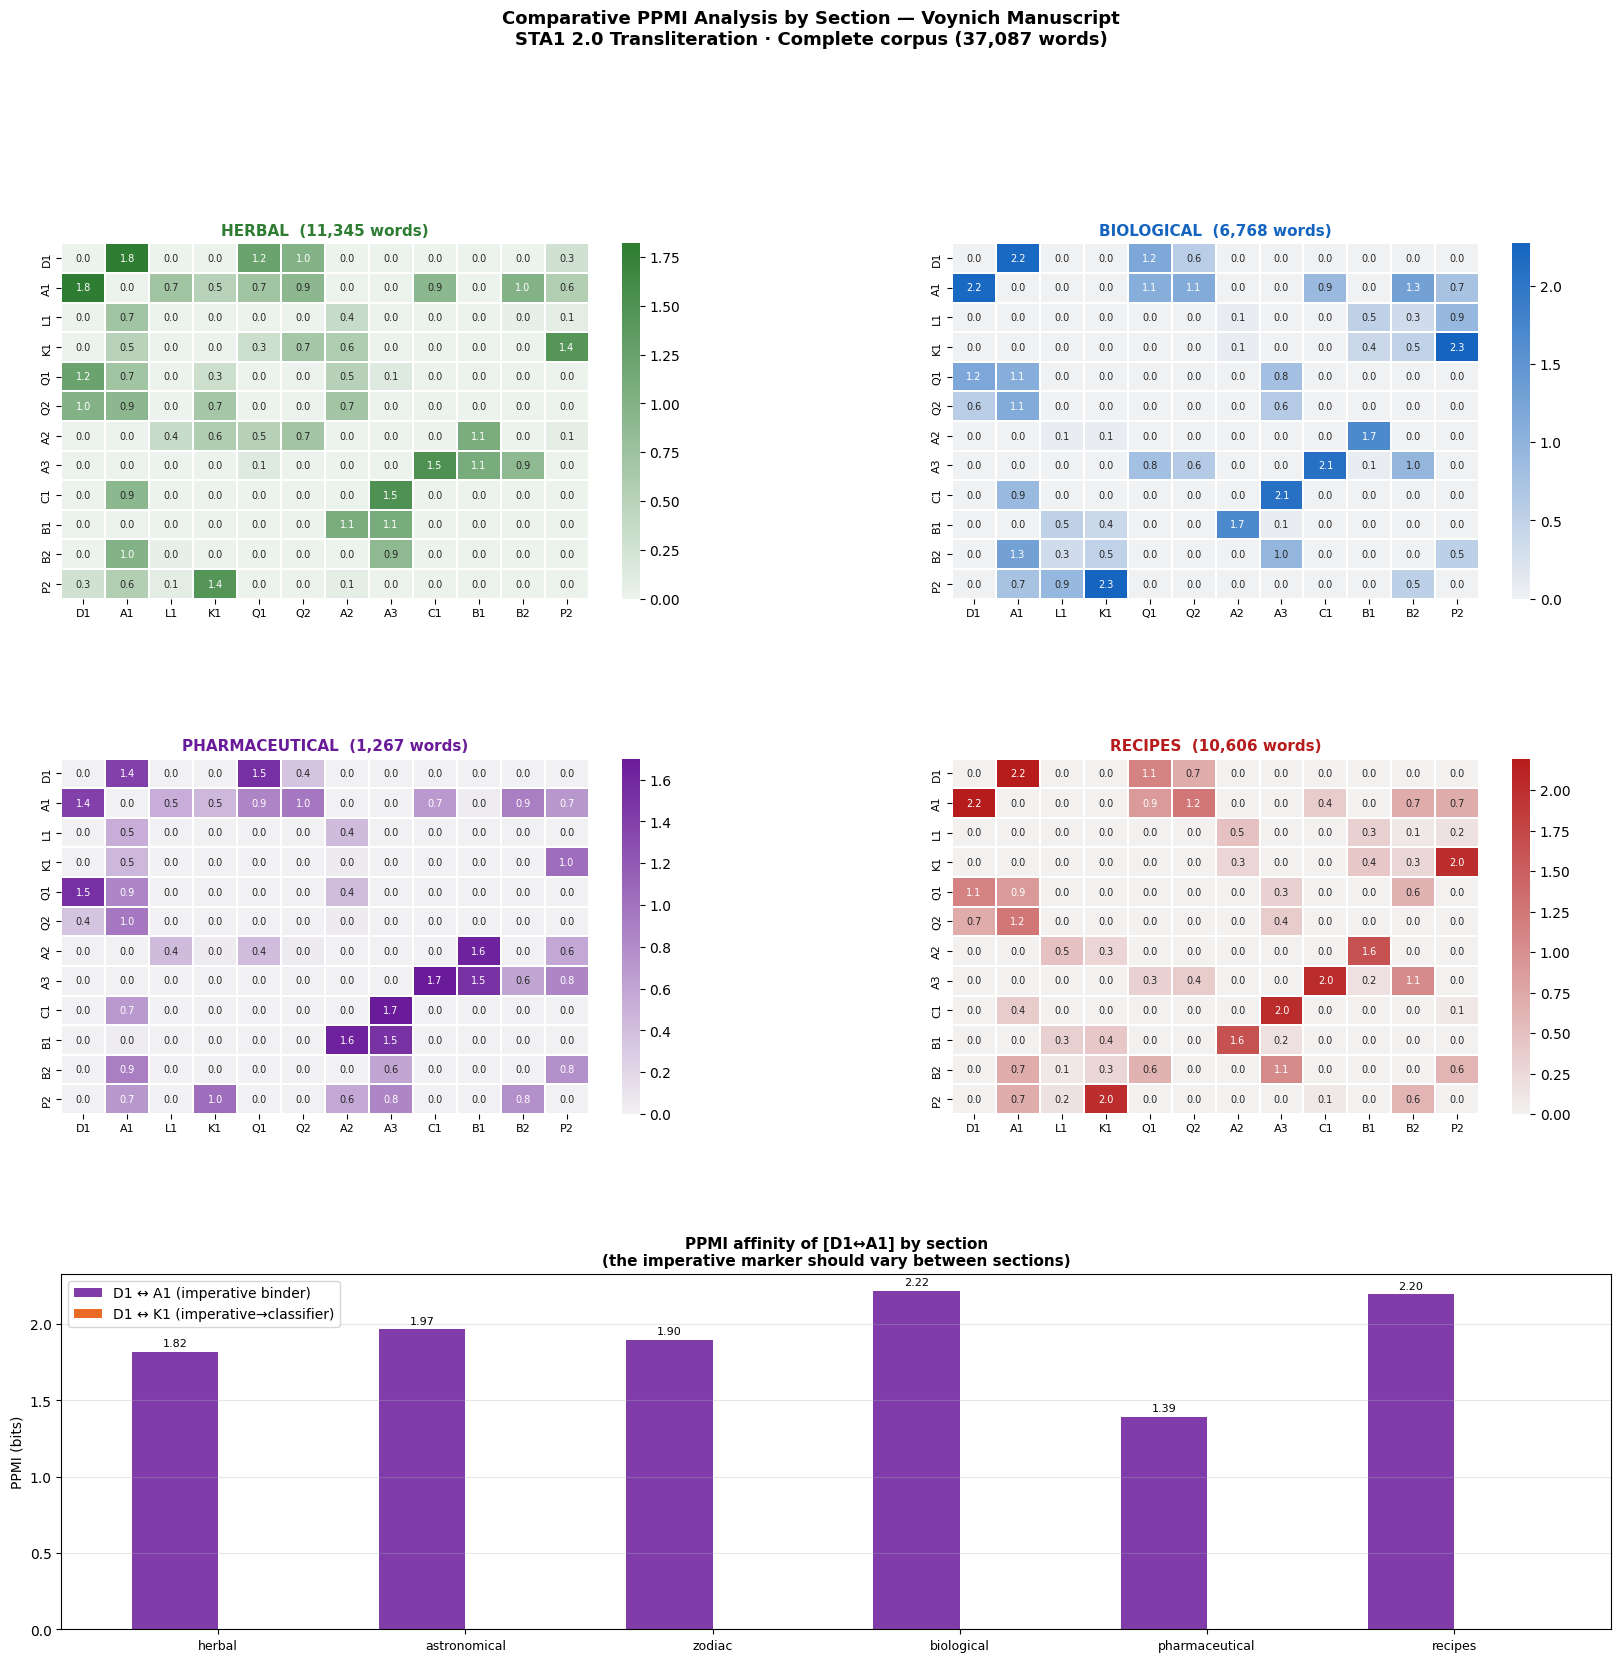


=== CURRIER TEST: TWO 'LANGUAGES'? ===

Morpheme    herbal  astronom  pharmace  biologic   recipes    A≠B?
─────────────────────────────────────────────────────────────────────────────────────
D1           24.25      4.38     26.41     58.18     41.26  B>2.7xA ←
A1          171.53    166.37    223.04    138.94    141.15  similar
A2          113.34    142.73     86.94    129.88    102.08  similar
A3           88.38    115.59     66.21     68.83    106.31  similar
C1           48.04     55.17     52.46     31.72     40.06  similar
K1           90.41     70.05     61.63     51.33     70.78  similar
L1           30.73     11.38     22.38     32.13     22.54  similar
Q1           56.68     68.30     61.81     70.25     69.32  similar
Q2           40.93     51.66     22.38     30.30     38.52  similar
B1           70.52     62.17     47.69     76.37     64.15  similar
B2           60.21     49.91     93.73     84.98     65.31  similar

(frequencies in occurrences per 1,000 glyphs)


In [13]:
import numpy as np
from collections import defaultdict, Counter
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import re

def parse_sta_with_sections(filepath, section_mapping):
    """
    Reads the STA file and groups words by section.
    Returns: dict {section: [list_of_words]}
    where each word is a list of glyphs.
    """
    words_by_section = defaultdict(list)
    current_folio = 'unknown'
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            
            # Detect folio change
            m_folio = re.match(r'^<(f\d+[rv][ab]?\d*)>', line)
            if m_folio:
                tag = m_folio.group(1)
                current_folio = tag
                continue
            
            # Extract glyph text
            match = re.match(r'^<[^>]+>\s+(.*)', line)
            if not match:
                continue
            text = match.group(1).strip()
            text = re.sub(r'\{[^}]*\}', '', text)
            text = re.sub(r'<[^>]*>', '', text)
            text = re.sub(r'-', '.', text)
            
            if not text:
                continue
            
            # Determine section of current folio
            section = section_mapping.get(current_folio, 'unknown')
            
            # Parse words
            for word_raw in text.split('.'):
                word_raw = word_raw.strip()
                if not word_raw:
                    continue
                glyphs = [g for g in re.findall(r'[A-Z][0-9a-z]?', word_raw)
                         if len(g) == 2]
                if glyphs:
                    words_by_section[section].append(glyphs)
    
    print("=== CORPUS BY SECTION ===\n")
    print(f"{'Section':<15} {'Words':>9} {'Glyphs':>9} {'Vocab':>7}")
    print("─" * 45)
    total_p = total_g = 0
    for sec in ['herbal','astronomical','zodiac','biological','pharmaceutical','recipes']:
        sec_words = words_by_section[sec]
        sec_glyphs = sum(len(p) for p in sec_words)
        vocab = len(set(g for p in sec_words for g in p))
        total_p += len(sec_words)
        total_g += sec_glyphs
        print(f"{sec:<15} {len(sec_words):>9,} {sec_glyphs:>9,} {vocab:>7}")
    print("─" * 45)
    print(f"{'TOTAL':<15} {total_p:>9,} {total_g:>9,}")
    
    return words_by_section


def compute_ppmi_section(words, window=2):
    """
    Computes PPMI matrix for a given section.
    Returns: (ppmi_matrix, ordered_vocab)
    """
    # Glyph frequencies
    freq = Counter(g for p in words for g in p)
    vocab = [g for g, _ in freq.most_common() if freq[g] >= 5]
    tok2idx = {g: i for i, g in enumerate(vocab)}
    n = len(vocab)
    
    # Co-occurrence matrix with distance weighting
    cooc = np.zeros((n, n))
    for word in words:
        for i, g in enumerate(word):
            if g not in tok2idx:
                continue
            start = max(0, i - window)
            end = min(len(word), i + window + 1)
            for j in range(start, end):
                if j != i and word[j] in tok2idx:
                    weight = 1.0 / abs(j - i)
                    cooc[tok2idx[g]][tok2idx[word[j]]] += weight
    
    # PPMI
    total = cooc.sum() + 1e-10
    marginal_freq = cooc.sum(axis=1) / total
    ppmi = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if cooc[i, j] > 0:
                p_ij = cooc[i, j] / total
                p_i = marginal_freq[i] + 1e-10
                p_j = marginal_freq[j] + 1e-10
                ppmi[i, j] = max(0, np.log2(p_ij / (p_i * p_j)))
    
    return ppmi, vocab, freq


def visualize_comparative_ppmi(words_by_section):
    """
    Generates 4 comparative PPMI heatmaps (main sections)
    focused on the already identified grammatical morphemes.
    """
    # Morphemes of interest — those already assigned a function
    key_morphemes = ['D1', 'A1', 'L1', 'K1', 'Q1', 'Q2', 
                      'A2', 'A3', 'C1', 'B1', 'B2', 'P2']
    
    main_sections = ['herbal', 'biological', 'pharmaceutical', 'recipes']
    section_colors = {
        'herbal':          '#2E7D32',
        'biological':      '#1565C0', 
        'pharmaceutical':  '#6A1B9A',
        'recipes':         '#B71C1C',
    }
    
    fig = plt.figure(figsize=(20, 18))
    gs = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)
    
    data_by_section = {}
    
    for idx, section in enumerate(main_sections):
        sec_words = words_by_section[section]
        ppmi, vocab, freq = compute_ppmi_section(sec_words)
        data_by_section[section] = (ppmi, vocab, freq)
        
        # Filter to key morphemes present in this section
        present = [m for m in key_morphemes if m in vocab]
        indices = [vocab.index(m) for m in present]
        
        if not indices:
            continue
        
        submatrix = ppmi[np.ix_(indices, indices)]
        
        ax = fig.add_subplot(gs[idx // 2, idx % 2])
        color = section_colors[section]
        
        # Heatmap with section-specific colormap
        cmap = sns.light_palette(color, as_cmap=True)
        sns.heatmap(submatrix,
                    xticklabels=present,
                    yticklabels=present,
                    cmap=cmap,
                    ax=ax,
                    annot=True,
                    fmt='.1f',
                    annot_kws={'size': 7},
                    linewidths=0.3)
        
        n_words = len(sec_words)
        ax.set_title(f"{section.upper()}  ({n_words:,} words)", 
                    fontsize=11, fontweight='bold', color=color)
        ax.tick_params(axis='both', labelsize=8)
    
    # Bottom panel: direct comparison of D1-A1 affinity by section
    ax_bar = fig.add_subplot(gs[2, :])
    ax_bar.set_title("PPMI affinity of [D1↔A1] by section\n"
                     "(the imperative marker should vary between sections)", 
                     fontsize=11, fontweight='bold')
    
    all_sections = ['herbal', 'astronomical', 'zodiac', 
                       'biological', 'pharmaceutical', 'recipes']
    ppmi_D1_A1 = []
    ppmi_D1_K1 = []
    labels = []
    
    for section in all_sections:
        sec_words = words_by_section[section]
        if len(sec_words) < 50:  # very small section
            ppmi_D1_A1.append(0)
            ppmi_D1_K1.append(0)
            labels.append(f"{section}\n(n<50)")
            continue
        
        ppmi, vocab, _ = compute_ppmi_section(sec_words)
        
        def get_ppmi_pair(g1, g2):
            if g1 in vocab and g2 in vocab:
                i, j = vocab.index(g1), vocab.index(g2)
                return (ppmi[i, j] + ppmi[j, i]) / 2
            return 0
        
        ppmi_D1_A1.append(get_ppmi_pair('D1', 'A1'))
        ppmi_D1_K1.append(get_ppmi_pair('D1', 'K1'))
        labels.append(section)
    
    x = np.arange(len(labels))
    width = 0.35
    bars1 = ax_bar.bar(x - width/2, ppmi_D1_A1, width, 
                        label='D1 ↔ A1 (imperative binder)',
                        color='#6A1B9A', alpha=0.85)
    bars2 = ax_bar.bar(x + width/2, ppmi_D1_K1, width,
                        label='D1 ↔ K1 (imperative→classifier)',
                        color='#E65100', alpha=0.85)
    
    ax_bar.set_xticks(x)
    ax_bar.set_xticklabels(labels, fontsize=9)
    ax_bar.set_ylabel("PPMI (bits)")
    ax_bar.legend()
    ax_bar.grid(True, alpha=0.3, axis='y')
    
    # Annotete values
    for bar in bars1 + bars2:
        h = bar.get_height()
        if h > 0.1:
            ax_bar.text(bar.get_x() + bar.get_width()/2., h + 0.02,
                       f'{h:.2f}', ha='center', va='bottom', fontsize=8)
    
    plt.suptitle("Comparative PPMI Analysis by Section — Voynich Manuscript\n"
                 "STA1 2.0 Transliteration · Complete corpus (37,087 words)",
                 fontsize=13, fontweight='bold', y=1.01)
    
    plt.savefig('images/ppmi_comparativo_secciones.png', dpi=150, bbox_inches='tight')
    plt.show()
    
    return data_by_section


def dialectal_analysis(data_by_section, words_by_section):
    """
    Currier test: do sections A and B have distinct statistical profiles?
    Sections A (Currier): herbal, astronomical, zodiac, pharmaceutical
    Sections B (Currier): biological, recipes
    """
    print("\n=== CURRIER TEST: TWO 'LANGUAGES'? ===\n")
    
    group_A = ['herbal', 'astronomical', 'pharmaceutical']
    group_B = ['biological', 'recipes']
    
    test_morphemes = ['D1', 'A1', 'A2', 'A3', 'C1', 'K1', 
                     'L1', 'Q1', 'Q2', 'B1', 'B2']
    
    print(f"{'Morpheme':<8}", end='')
    for sec in group_A + group_B:
        print(f"{sec[:8]:>10}", end='')
    print(f"  {'A≠B?':>6}")
    print("─" * 85)
    
    for morpheme in test_morphemes:
        freqs = []
        print(f"{morpheme:<8}", end='')
        
        for section in group_A + group_B:
            sec_words = words_by_section[section]
            if not sec_words:
                freqs.append(0)
                print(f"{'N/A':>10}", end='')
                continue
            total_glyphs = sum(len(p) for p in sec_words)
            count = sum(p.count(morpheme) for p in sec_words)
            rel_freq = count / total_glyphs * 1000  # per thousand glyphs
            freqs.append(rel_freq)
            print(f"{rel_freq:>10.2f}", end='')
        
        # Is there a difference between groups A and B?
        mean_A = np.mean(freqs[:len(group_A)])
        mean_B = np.mean(freqs[len(group_A):])
        ratio = mean_A / (mean_B + 0.01)
        
        if ratio > 1.5:
            signal = f"  A>{ratio:.1f}xB ←"
        elif ratio < 0.67:
            signal = f"  B>{1/ratio:.1f}xA ←"
        else:
            signal = "  similar"
        print(signal)
    
    print("\n(frequencies in occurrences per 1,000 glyphs)")


# ── RUN ALL ────────────────────────────────────────────────────
words_by_section = parse_sta_with_sections(
    'corpus/voynich_sta.txt',   # ← adjust the path
    section_mapping
)

data = visualize_comparative_ppmi(words_by_section)
dialectal_analysis(data, words_by_section)

=== POSITIONAL PROFILE BY SECTION ===
(does the grammatical function of a morpheme change between sections?)


  D1:
  Section            Start   Middle      End      n
  ──────────────────────────────────────────────────
  herbal             98.0%     2.0%     0.1%   1125
  biological         98.7%     1.2%     0.1%   1682
  pharmaceutical     97.9%     2.1%     0.0%    144
  recipes            99.7%     0.3%     0.0%   1884

  A1:
  Section            Start   Middle      End      n
  ──────────────────────────────────────────────────
  herbal             33.5%    56.3%    10.2%   7959
  biological         54.2%    42.7%     3.1%   4017
  pharmaceutical     35.0%    54.4%    10.6%   1216
  recipes            49.8%    43.5%     6.7%   6445

  A2:
  Section            Start   Middle      End      n
  ──────────────────────────────────────────────────
  herbal             13.9%    11.3%    74.7%   5259
  biological          3.6%     3.7%    92.7%   3755
  pharmaceutical     10.8%     4.9

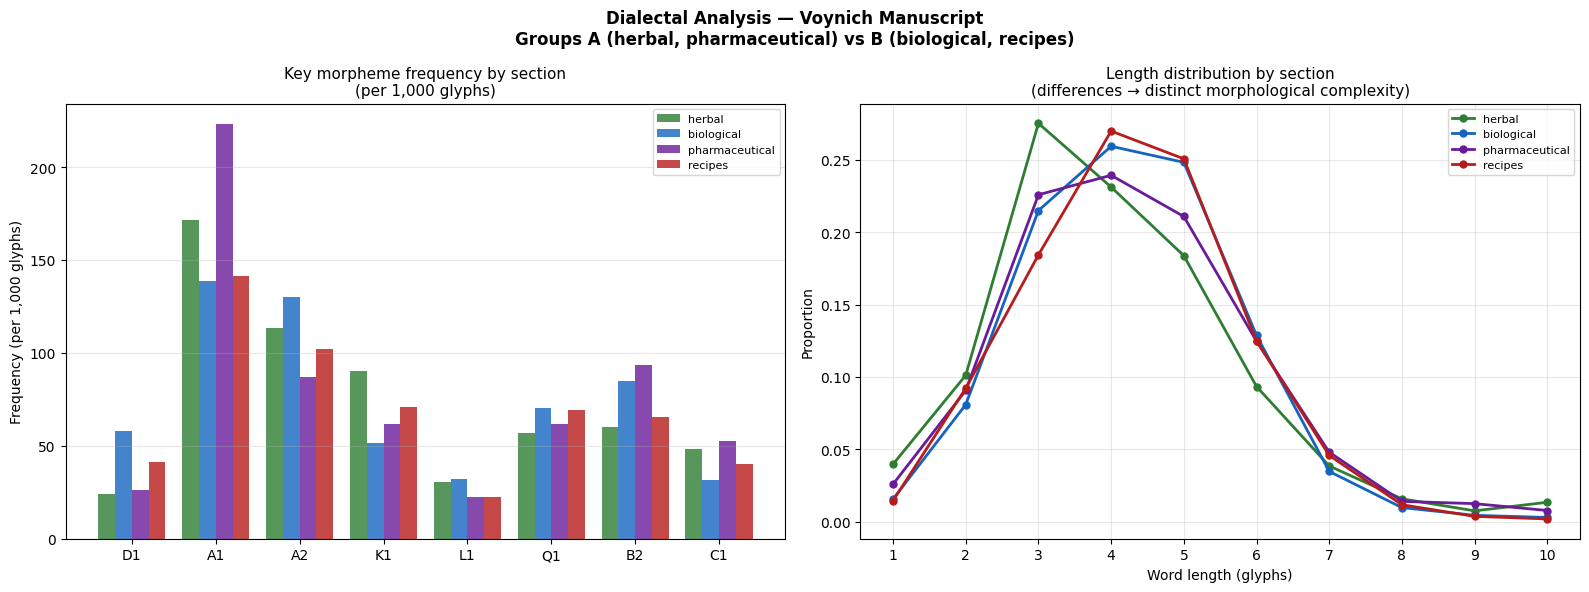

In [14]:
def deep_dialectal_analysis(words_by_section, data_by_section):
    """
    Compares positional profiles of key morphemes between sections.
    If D1 has the same positional profile across all sections → same morpheme.
    If the profile changes → different usage of the same glyph.
    """
    key_morphemes = ['D1', 'A1', 'A2', 'K1', 'L1', 'Q1', 'B1', 'B2']
    sections = ['herbal', 'biological', 'pharmaceutical', 'recipes']
    
    # ── 1. Positional profile by section ────────────────────────────
    print("=== POSITIONAL PROFILE BY SECTION ===")
    print("(does the grammatical function of a morpheme change between sections?)\n")
    
    profiles = defaultdict(dict)  # profiles[morpheme][section] = (start, middle, end)
    
    for section in sections:
        sec_words = words_by_section[section]
        for morpheme in key_morphemes:
            positions = []
            for word in sec_words:
                if morpheme not in word:
                    continue
                n = len(word)
                for i, g in enumerate(word):
                    if g == morpheme:
                        rel_pos = 0.5 if n == 1 else i / (n - 1)
                        positions.append(rel_pos)
            
            if not positions:
                profiles[morpheme][section] = None
                continue
            
            start  = sum(1 for p in positions if p < 0.25) / len(positions)
            middle = sum(1 for p in positions if 0.25 <= p <= 0.75) / len(positions)
            end    = sum(1 for p in positions if p > 0.75) / len(positions)
            profiles[morpheme][section] = (start, middle, end, len(positions))
    
    # Print comparative table
    for morpheme in key_morphemes:
        print(f"\n  {morpheme}:")
        print(f"  {'Section':<15} {'Start':>8} {'Middle':>8} {'End':>8} {'n':>6}")
        print(f"  {'─'*50}")
        for section in sections:
            p = profiles[morpheme][section]
            if p is None:
                print(f"  {section:<15} {'N/A':>8}")
                continue
            start, middle, end, n = p
            # Flag if there is a significant difference from global
            flag = ''
            if morpheme == 'D1' and start < 0.90:
                flag = ' ← different!'
            print(f"  {section:<15} {start:>8.1%} {middle:>8.1%} {end:>8.1%} {n:>6}{flag}")
    
    # ── 2. Mean word length by section ─────────────────────
    print("\n\n=== MEAN WORD LENGTH BY SECTION ===")
    print("(different lengths → different morphological complexity)\n")
    print(f"  {'Section':<15} {'Mean':>7} {'Median':>9} {'% 1-glyph':>11} {'% 4-5 glyph':>13}")
    print(f"  {'─'*60}")
    
    for section in sections:
        sec_words = words_by_section[section]
        if not sec_words:
            continue
        lengths = [len(p) for p in sec_words]
        mean = np.mean(lengths)
        median = np.median(lengths)
        pct_1 = sum(1 for l in lengths if l == 1) / len(lengths)
        pct_45 = sum(1 for l in lengths if l in [4, 5]) / len(lengths)
        print(f"  {section:<15} {mean:>7.2f} {median:>9.1f} {pct_1:>11.1%} {pct_45:>13.1%}")
    
    # ── 3. Exclusive initial bigrams per section ─────────────
    print("\n\n=== EXCLUSIVE INITIAL BIGRAMS BY SECTION ===")
    print("(bigrams that appear ONLY in one section → dialectal vocabulary)\n")
    
    bigrams_by_section = {}
    for section in sections:
        sec_words = words_by_section[section]
        bg = Counter()
        for p in sec_words:
            if len(p) >= 2:
                bg[tuple(p[:2])] += 1
        bigrams_by_section[section] = bg
    
    all_bigrams = set()
    for bg in bigrams_by_section.values():
        all_bigrams.update(bg.keys())
    
    for section in sections:
        bg_sec = bigrams_by_section[section]
        # Bigrams appearing ≥10 times in this section and <3 in all others
        exclusive = []
        for bigram, count in bg_sec.items():
            if count < 10:
                continue
            total_others = sum(
                bigrams_by_section[s].get(bigram, 0)
                for s in sections if s != section
            )
            if total_others < 5:
                exclusive.append((bigram, count))
        
        exclusive.sort(key=lambda x: -x[1])
        print(f"  {section.upper()} — {len(exclusive)} exclusive bigrams:")
        for bg, cnt in exclusive[:8]:
            print(f"    {bg[0]}-{bg[1]:<12} {cnt:>5}x")
        print()
    
    # ── 4. Visualization: dialectal profile radar ───────────────────
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Left panel: relative frequency of key morphemes by section
    morphemes_plot = ['D1', 'A1', 'A2', 'K1', 'L1', 'Q1', 'B2', 'C1']
    x = np.arange(len(morphemes_plot))
    width = 0.2
    colors = ['#2E7D32', '#1565C0', '#6A1B9A', '#B71C1C']
    
    ax = axes[0]
    for i, section in enumerate(sections):
        sec_words = words_by_section[section]
        total = sum(len(p) for p in sec_words)
        freqs = []
        for m in morphemes_plot:
            count = sum(p.count(m) for p in sec_words)
            freqs.append(count / total * 1000)
        
        offset = (i - 1.5) * width
        ax.bar(x + offset, freqs, width, label=section, 
               color=colors[i], alpha=0.8)
    
    ax.set_xticks(x)
    ax.set_xticklabels(morphemes_plot, fontsize=10)
    ax.set_title("Key morpheme frequency by section\n(per 1,000 glyphs)", 
                fontsize=11)
    ax.set_ylabel("Frequency (per 1,000 glyphs)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')
    
    # Right panel: length distribution by section
    ax2 = axes[1]
    max_len = 10
    for i, section in enumerate(sections):
        sec_words = words_by_section[section]
        lengths = [min(len(p), max_len) for p in sec_words]
        dist = Counter(lengths)
        total = len(lengths)
        xs = list(range(1, max_len + 1))
        ys = [dist.get(l, 0) / total for l in xs]
        ax2.plot(xs, ys, marker='o', label=section, 
                color=colors[i], linewidth=2, markersize=5)
    
    ax2.set_xlabel("Word length (glyphs)")
    ax2.set_ylabel("Proportion")
    ax2.set_title("Length distribution by section\n"
                 "(differences → distinct morphological complexity)", fontsize=11)
    ax2.legend(fontsize=8)
    ax2.grid(True, alpha=0.3)
    ax2.set_xticks(range(1, max_len + 1))
    
    plt.suptitle("Dialectal Analysis — Voynich Manuscript\n"
                "Groups A (herbal, pharmaceutical) vs B (biological, recipes)",
                fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('images/analisis_dialectal.png', dpi=150, bbox_inches='tight')
    plt.show()


# Run
deep_dialectal_analysis(words_by_section, data)

Filtered vocabulary (freq>=20): 44 glyphs
Nodes: 44
Edges (PPMI>0.3): 198


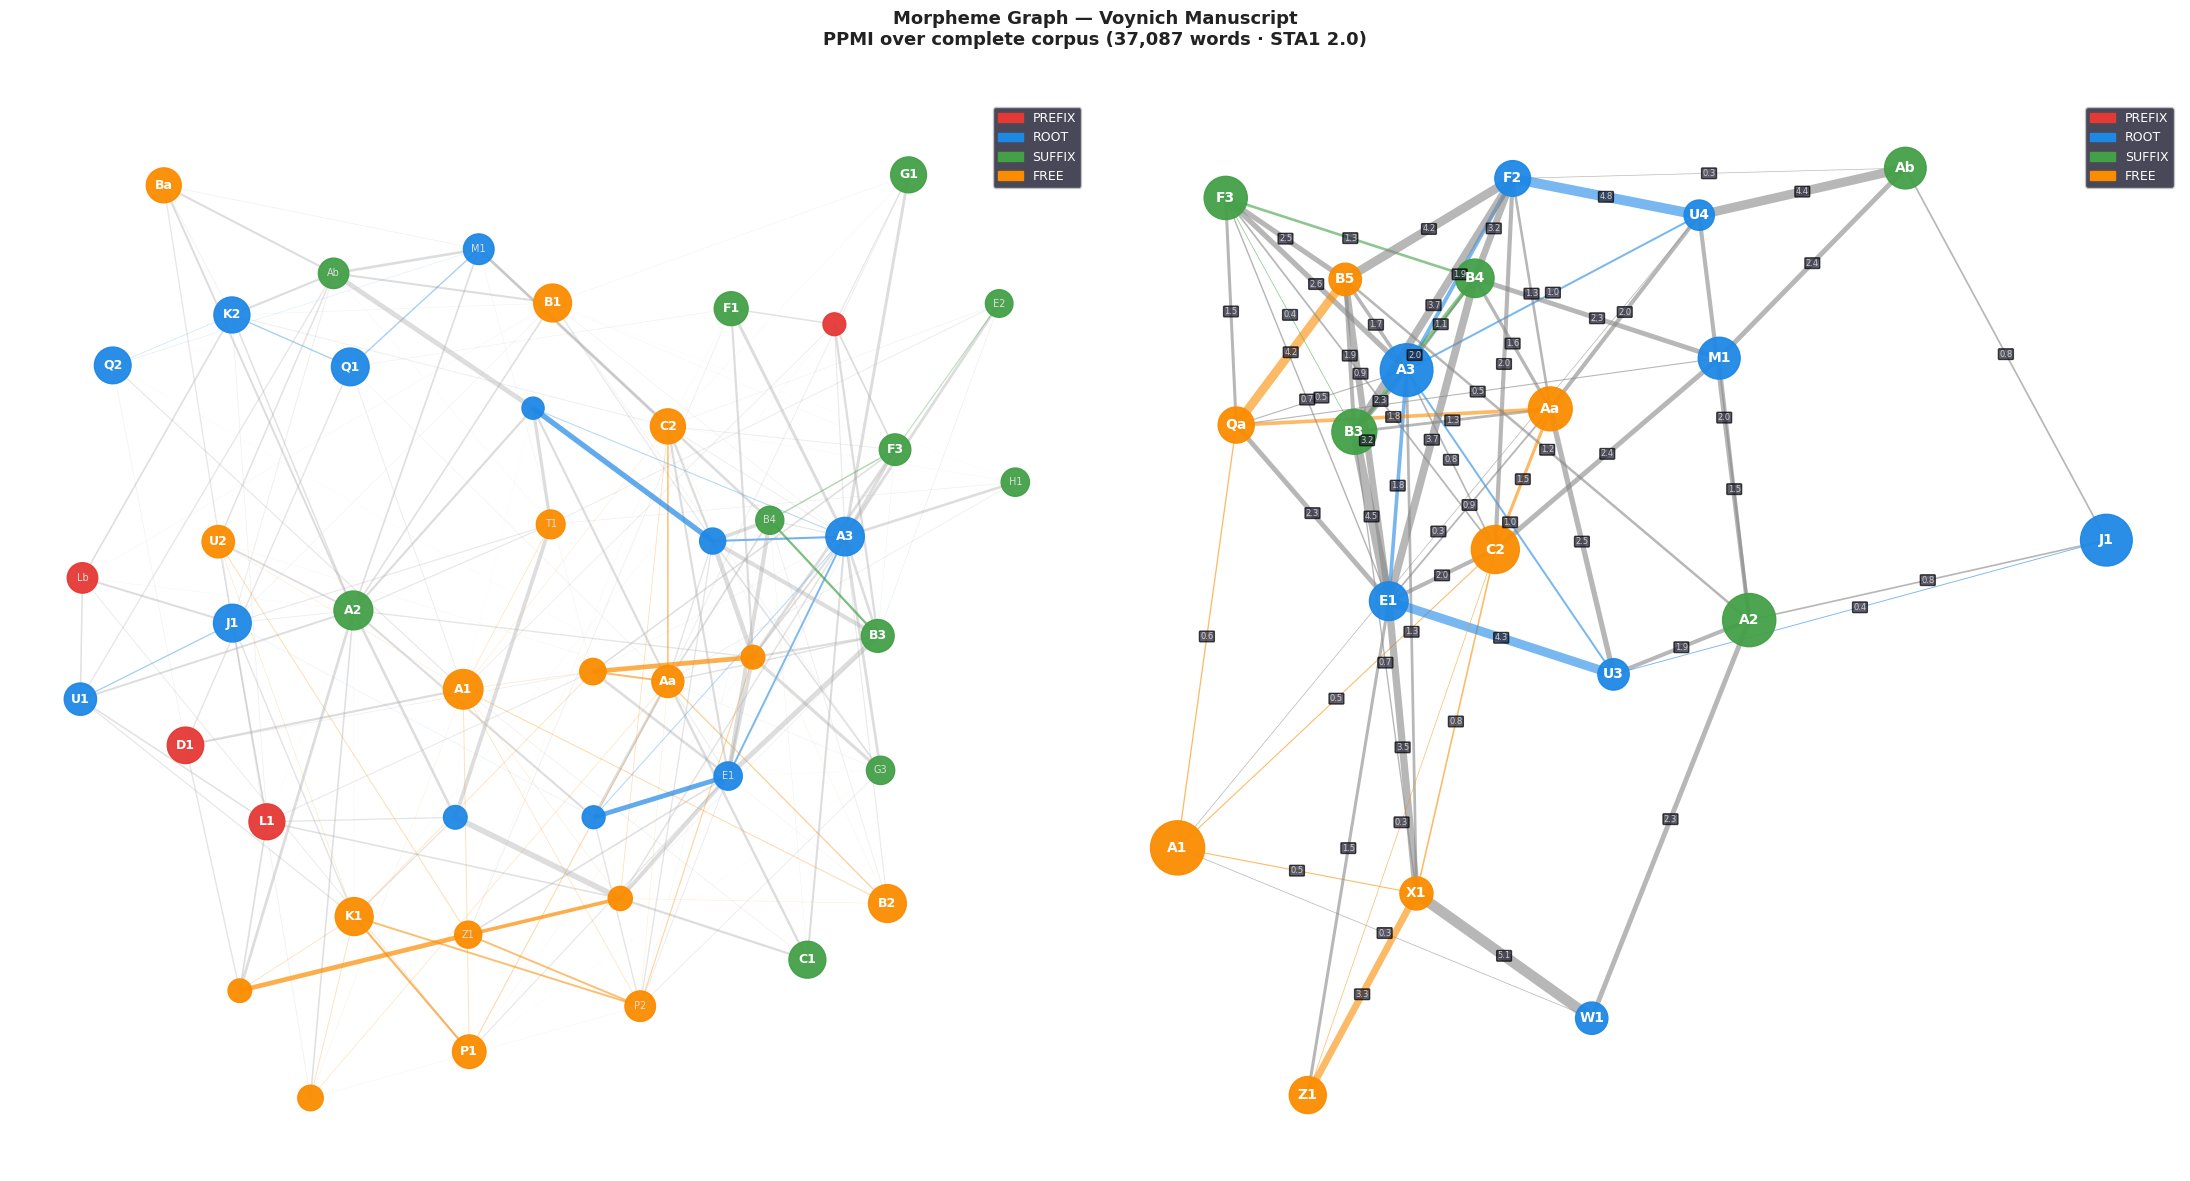


=== DETECTED COMMUNITIES (Louvain) ===

Community 1 (15 nodes, dominant: FREE):
  A2, K1, B1, J1, K2, L1, Ba, P1, U2, U1, M1, Lb...
Community 2 (10 nodes, dominant: FREE):
  B3, Aa, P2, E1, G3, B4, Qa, F2, B5, U3
Community 3 (8 nodes, dominant: SUFFIX):
  A3, G1, C2, F1, F3, H1, E2, Cd
Community 4 (6 nodes, dominant: FREE):
  C1, T1, Z1, X1, W1, W2
Community 5 (5 nodes, dominant: ROOT):
  A1, B2, Q1, Q2, D1


In [15]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from collections import Counter, defaultdict

def build_morpheme_graph(words_by_section, ppmi_threshold=0.3, freq_threshold=20):
    """
    Builds a morpheme graph from the complete corpus.
    
    Nodes: glyphs with frequency > freq_threshold
    Edges: PPMI > ppmi_threshold between glyph pairs
    Node color: grammatical function (PRE/ROOT/SUF/FREE)
    Edge thickness: PPMI value
    """
    # ── Complete corpus ──────────────────────────────────────────────
    all_words = []
    for sec_words in words_by_section.values():
        all_words.extend(sec_words)
    
    # ── Global frequencies ─────────────────────────────────────────
    freq = Counter(g for p in all_words for g in p)
    vocab = [g for g, c in freq.most_common() if c >= freq_threshold]
    tok2idx = {g: i for i, g in enumerate(vocab)}
    n = len(vocab)
    print(f"Filtered vocabulary (freq>={freq_threshold}): {n} glyphs")
    
    # ── Global PPMI matrix ───────────────────────────────────────────
    cooc = np.zeros((n, n))
    for word in all_words:
        for i, g in enumerate(word):
            if g not in tok2idx:
                continue
            for j in range(max(0, i-2), min(len(word), i+3)):
                if j != i and word[j] in tok2idx:
                    weight = 1.0 / abs(j - i)
                    cooc[tok2idx[g]][tok2idx[word[j]]] += weight
    
    total = cooc.sum() + 1e-10
    freq_m = cooc.sum(axis=1) / total
    ppmi = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if cooc[i, j] > 0:
                p_ij = cooc[i, j] / total
                ppmi[i, j] = max(0, np.log2(p_ij / (freq_m[i] * freq_m[j] + 1e-10)))
    
    # ── Functional classification (from prior positional analysis) ─────
    PREFIXES = {'D1', 'L1', 'Da', 'S2', 'U7', 'Cd', 'Lb'}
    ROOTS    = {'Q1', 'Q2', 'A3', 'J1', 'K2', 'M1', 'N1', 
                'U1', 'U3', 'U4', 'V1', 'V2', 'W1', 'E1', 'F2', 'G2'}
    SUFFIXES = {'A2', 'C1', 'G1', 'B3', 'B4', 'F1', 'F3', 
                'E2', 'Ab', 'G3', 'H1'}
    
    def classify(g):
        if g in PREFIXES: return 'PREFIX'
        if g in ROOTS:    return 'ROOT'
        if g in SUFFIXES: return 'SUFFIX'
        return 'FREE'
    
    func_colors = {
        'PREFIX': '#E53935',   # red
        'ROOT':   '#1E88E5',   # blue
        'SUFFIX': '#43A047',   # green
        'FREE':   '#FB8C00',   # orange
    }
    
    # ── Build NetworkX graph ─────────────────────────────────────
    G = nx.Graph()
    
    # Add nodes
    for g in vocab:
        G.add_node(g,
            function=classify(g),
            freq=freq[g],
            color=func_colors[classify(g)]
        )
    
    # Add edges (symmetric PPMI)
    for i, g1 in enumerate(vocab):
        for j, g2 in enumerate(vocab):
            if j <= i:
                continue
            ppmi_val = (ppmi[i, j] + ppmi[j, i]) / 2
            if ppmi_val > ppmi_threshold:
                G.add_edge(g1, g2, weight=ppmi_val)
    
    print(f"Nodes: {G.number_of_nodes()}")
    print(f"Edges (PPMI>{ppmi_threshold}): {G.number_of_edges()}")
    
    return G, vocab, freq, ppmi, tok2idx, func_colors


def visualize_morpheme_graph(G, freq, func_colors):
    """
    Two-panel visualization:
    - Left: complete graph with clusters by function
    - Right: core subgraph (most connected morphemes)
    """
    fig, axes = plt.subplots(1, 2, figsize=(22, 12))
    
    # ── Layout: spring with fixed seed ─────────────────────────────
    # Separate by function using initial position as prior
    pos_prior = {}
    centers = {
        'PREFIX': (-2.0,  0.5),
        'ROOT':   ( 0.0,  0.0),
        'SUFFIX': ( 2.0,  0.5),
        'FREE':   ( 0.0, -1.5),
    }
    for node in G.nodes():
        func = G.nodes[node]['function']
        cx, cy = centers[func]
        # Small random offset around the center
        rng = np.random.default_rng(hash(node) % 10000)
        pos_prior[node] = (cx + rng.uniform(-0.8, 0.8),
                           cy + rng.uniform(-0.5, 0.5))
    
    pos = nx.spring_layout(G, pos=pos_prior, k=0.8, 
                           iterations=80, seed=42,
                           weight='weight')
    
    # ── Left panel: complete graph ──────────────────────────────
    ax1 = axes[0]
    ax1.set_facecolor('#0d1117')
    ax1.set_title("Complete Morphological Network of the Voynich\n"
                  "Nodes = glyphs · Edges = PPMI affinity · "
                  "Color = grammatical function",
                  fontsize=11, color='white', pad=12)
    
    # Draw edges with thickness and opacity by weight
    edges = G.edges(data=True)
    for u, v, d in edges:
        w = d['weight']
        # Edge color by function of the pair
        f1 = G.nodes[u]['function']
        f2 = G.nodes[v]['function']
        if f1 == f2:
            edge_color = func_colors[f1]
            alpha = min(0.7, w / 3)
        else:
            edge_color = '#aaaaaa'
            alpha = min(0.4, w / 4)
        
        nx.draw_networkx_edges(G, pos, edgelist=[(u, v)],
                               width=w * 0.8,
                               alpha=alpha,
                               edge_color=edge_color,
                               ax=ax1)
    
    # Node size proportional to log of frequency
    node_sizes = [np.log(freq[n] + 1) * 80 for n in G.nodes()]
    node_colors = [G.nodes[n]['color'] for n in G.nodes()]
    
    nx.draw_networkx_nodes(G, pos,
                           node_size=node_sizes,
                           node_color=node_colors,
                           alpha=0.95,
                           ax=ax1)
    
    # Labels — only for large (frequent) nodes
    large_labels = {n: n for n in G.nodes() if freq[n] > 500}
    medium_labels = {n: n for n in G.nodes() 
                      if 100 < freq[n] <= 500}
    
    nx.draw_networkx_labels(G, pos, labels=large_labels,
                            font_size=9, font_color='white',
                            font_weight='bold', ax=ax1)
    nx.draw_networkx_labels(G, pos, labels=medium_labels,
                            font_size=7, font_color='#dddddd',
                            ax=ax1)
    
    # Legend
    legend = [mpatches.Patch(color=c, label=f) 
               for f, c in func_colors.items()]
    ax1.legend(handles=legend, loc='upper right',
               facecolor='#1a1a2e', labelcolor='white',
               fontsize=9)
    ax1.axis('off')
    
    # ── Right panel: core subgraph (top 20 by degree) ──────────────
    ax2 = axes[1]
    ax2.set_facecolor('#0d1117')
    ax2.set_title("Core Subgraph — Top 20 most connected morphemes\n"
                  "(edge thickness = PPMI · annotated with values)",
                  fontsize=11, color='white', pad=12)
    
    # Top 20 by weighted degree
    weighted_degree = {n: sum(d['weight'] for _, _, d in G.edges(n, data=True))
                  for n in G.nodes()}
    top20 = sorted(weighted_degree.keys(), key=lambda x: -weighted_degree[x])[:20]
    
    G_core = G.subgraph(top20).copy()
    pos_core = nx.spring_layout(G_core, k=1.2, iterations=100, 
                                 seed=42, weight='weight')
    
    # Edges with PPMI annotetion
    for u, v, d in G_core.edges(data=True):
        w = d['weight']
        f1 = G_core.nodes[u]['function']
        f2 = G_core.nodes[v]['function']
        color_a = func_colors[f1] if f1 == f2 else '#888888'
        
        nx.draw_networkx_edges(G_core, pos_core,
                               edgelist=[(u, v)],
                               width=w * 1.5,
                               alpha=0.6,
                               edge_color=color_a,
                               ax=ax2)
        # Annotete PPMI on the edge
        mx = (pos_core[u][0] + pos_core[v][0]) / 2
        my = (pos_core[u][1] + pos_core[v][1]) / 2
        ax2.text(mx, my, f'{w:.1f}', fontsize=6,
                color='#cccccc', ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.1', 
                         facecolor='#1a1a2e', alpha=0.7))
    
    # Core nodes
    sizes_core = [np.log(freq[n] + 1) * 150 for n in G_core.nodes()]
    colors_core = [G_core.nodes[n]['color'] for n in G_core.nodes()]
    
    nx.draw_networkx_nodes(G_core, pos_core,
                           node_size=sizes_core,
                           node_color=colors_core,
                           alpha=0.95, ax=ax2)
    nx.draw_networkx_labels(G_core, pos_core,
                            font_size=10, font_color='white',
                            font_weight='bold', ax=ax2)
    
    ax2.legend(handles=legend, loc='upper right',
               facecolor='#1a1a2e', labelcolor='white',
               fontsize=9)
    ax2.axis('off')
    
    plt.suptitle("Morpheme Graph — Voynich Manuscript\n"
                 "PPMI over complete corpus (37,087 words · STA1 2.0)",
                 fontsize=13, fontweight='bold', color='#222222')
    
    plt.tight_layout()
    plt.savefig('images/grafo_morfemas_voynich.png', dpi=180, 
                bbox_inches='tight', facecolor='white')
    plt.show()
    
    # ── Report detected communities ────────────────────────────
    print("\n=== DETECTED COMMUNITIES (Louvain) ===\n")
    try:
        from networkx.algorithms import community
        communities = community.louvain_communities(G, seed=42, weight='weight')
        communities = sorted(communities, key=len, reverse=True)
        
        for i, com in enumerate(communities):
            functions = Counter(G.nodes[n]['function'] for n in com)
            dominant_func = functions.most_common(1)[0][0]
            members = sorted(com, key=lambda x: -freq[x])
            print(f"Community {i+1} ({len(com)} nodes, dominant: {dominant_func}):")
            print(f"  {', '.join(members[:12])}"
                  f"{'...' if len(members)>12 else ''}")
    except Exception as e:
        print(f"Louvain not available: {e}")
        print("Install with: pip install python-louvain --break-system-packages")
    
    return G_core, top20


# ── Install networkx if not present ────────────────────────────────
# pip install networkx --break-system-packages

# ── Run ────────────────────────────────────────────────────────
G, vocab, freq, ppmi_matrix, tok2idx, func_colors = build_morpheme_graph(
    words_by_section,
    ppmi_threshold=0.3,
    freq_threshold=20
)

G_core, top20 = visualize_morpheme_graph(G, freq, func_colors)

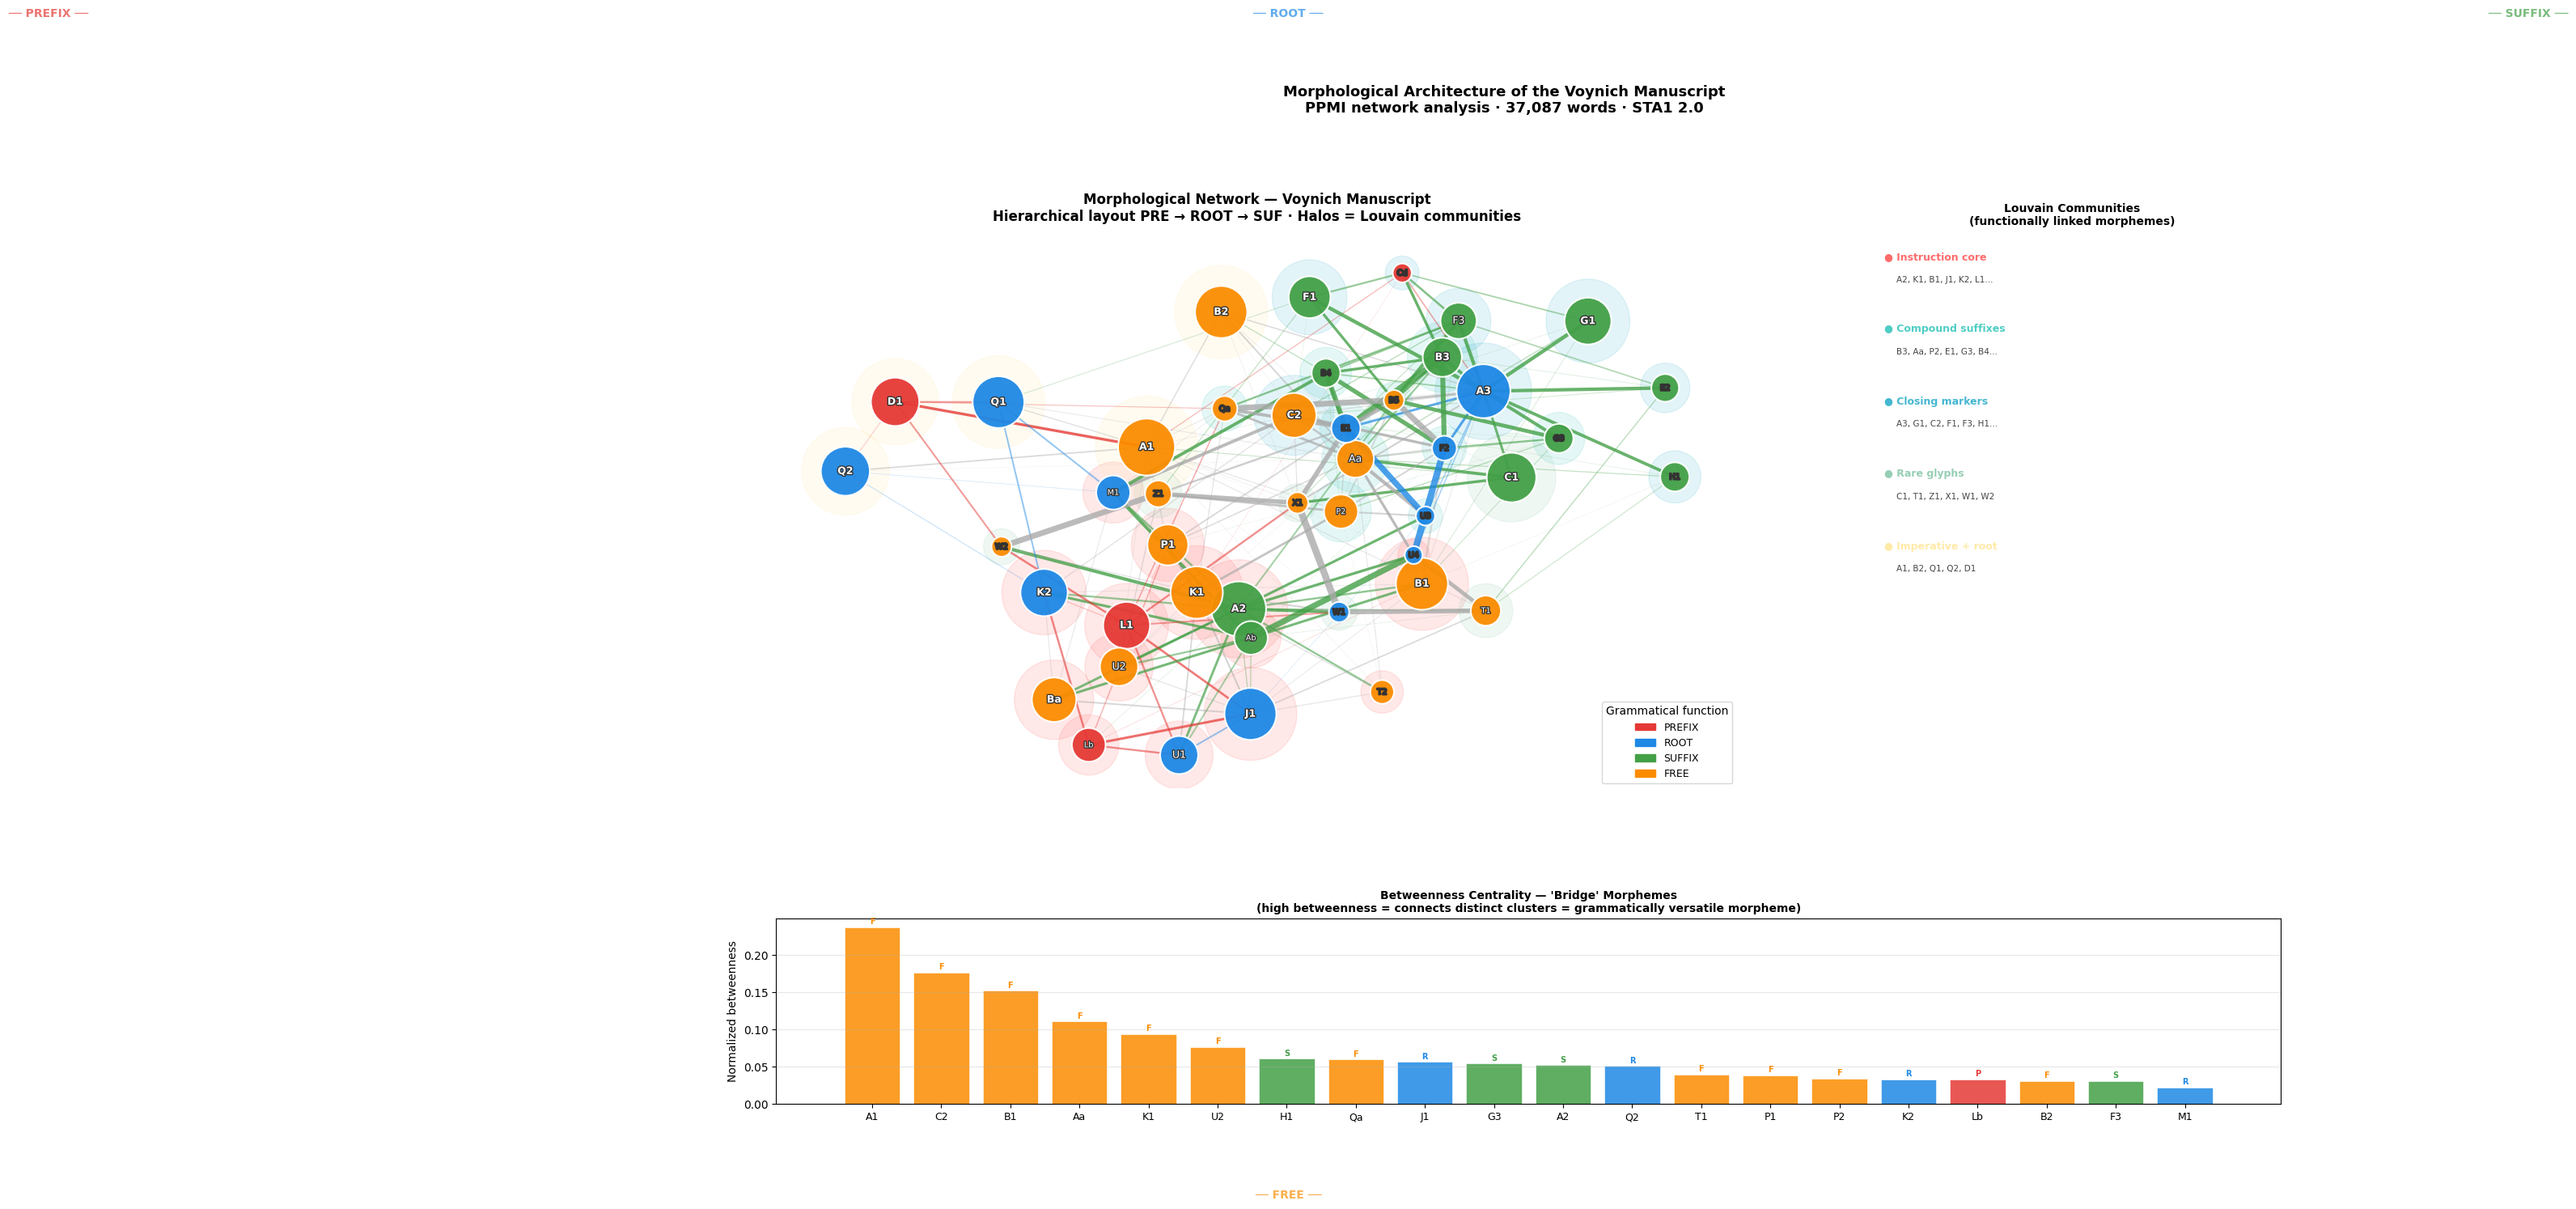


=== BRIDGE MORPHEMES (top betweenness) ===
Morpheme  Betweenness Function     Interpretation
─────────────────────────────────────────────────────────────────
A1             0.2370 FREE         Universal binder — connects all clusters
C2             0.1761 FREE         Inner block nexus
B1             0.1517 FREE         Versatile free — appears in all contexts
Aa             0.1107 FREE         —
K1             0.0941 FREE         Classifier — PRE↔ROOT bridge
U2             0.0764 FREE         —
H1             0.0609 SUFFIX       —
Qa             0.0598 FREE         —
J1             0.0565 ROOT         —
G3             0.0543 SUFFIX       —
A2             0.0520 SUFFIX       Dominant suffix — universal endpoint
Q2             0.0509 ROOT         —


In [16]:
def morpheme_graph_v2(G, freq, ppmi_matrix, tok2idx, vocab, func_colors):
    """
    Improved version with:
    - Hierarchical layout left→center→right by function
    - Edges colored by relationship type (intra vs inter-function)
    - Louvain communities overlaid as halos
    - Centrality panel to identify the most "bridge" morphemes
    """
    from networkx.algorithms import community as nx_community
    import matplotlib.patheffects as pe
    
    fig = plt.figure(figsize=(24, 14))
    gs = plt.GridSpec(2, 3, figure=fig, 
                      height_ratios=[3, 1],
                      hspace=0.35, wspace=0.3)
    
    ax_main  = fig.add_subplot(gs[0, :2])   # main graph (2/3 width)
    ax_com   = fig.add_subplot(gs[0, 2])    # community detail
    ax_cent  = fig.add_subplot(gs[1, :])    # bridge centrality
    
    # ── Hierarchical layout by function ───────────────────────────
    ORDER_X = {'PREFIX': -3.0, 'ROOT': 0.0, 'SUFFIX': 3.0, 'FREE': 0.0}
    ORDER_Y = {'PREFIX':  0.5, 'ROOT': 0.5, 'SUFFIX': 0.5, 'FREE': -1.8}
    
    pos = {}
    counters = defaultdict(int)
    groups = defaultdict(list)
    for n in G.nodes():
        groups[G.nodes[n]['function']].append(n)
    
    for func, nodes in groups.items():
        sorted_nodes = sorted(nodes, key=lambda x: -freq[x])
        n_nodes = len(sorted_nodes)
        for i, node in enumerate(sorted_nodes):
            # Distribute vertically within each function
            if func == 'FREE':
                # FREE in lower arc
                angle = np.pi + (i / max(n_nodes - 1, 1)) * np.pi
                radius = 1.8 + (i % 3) * 0.4
                x = radius * np.cos(angle)
                y = -1.5 + radius * np.sin(angle) * 0.4
            else:
                x = ORDER_X[func] + np.sin(i * 1.3) * 0.6
                y = ORDER_Y[func] + (i - n_nodes/2) * 0.35
            pos[node] = (x, y)
    
    # Refine with spring layout using positions as anchor
    pos = nx.spring_layout(G, pos=pos, k=0.6, iterations=60, 
                           seed=42, weight='weight')
    
    # ── Louvain communities ──────────────────────────────────────
    communities = nx_community.louvain_communities(G, seed=42, weight='weight')
    communities = sorted(communities, key=len, reverse=True)
    
    community_colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', 
                   '#FFEAA7', '#DDA0DD', '#98D8C8']
    node_to_community = {}
    for i, com in enumerate(communities):
        for n in com:
            node_to_community[n] = i
    
    # ── Draw main graph ──────────────────────────────────────
    ax_main.set_facecolor('#f8f9fa')
    ax_main.set_title("Morphological Network — Voynich Manuscript\n"
                      "Hierarchical layout PRE → ROOT → SUF · "
                      "Halos = Louvain communities",
                      fontsize=12, fontweight='bold', pad=10)
    
    # Community halos (circles behind nodes)
    for i, com in enumerate(communities[:6]):
        halo_color = community_colors[i]
        xs = [pos[n][0] for n in com]
        ys = [pos[n][1] for n in com]
        ax_main.scatter(xs, ys, s=[np.log(freq[n]+1)**2 * 80 for n in com],
                    color=halo_color, alpha=0.15, zorder=1)

    
    # Edges
    for u, v, d in G.edges(data=True):
        w = d['weight']
        f1 = G.nodes[u]['function']
        f2 = G.nodes[v]['function']
        
        # Color and style by relationship type
        if f1 == 'PREFIX' and f2 in ('ROOT', 'FREE'):
            color_e, style = '#E53935', 'solid'    # red: PRE→ROOT
        elif f2 == 'PREFIX' and f1 in ('ROOT', 'FREE'):
            color_e, style = '#E53935', 'solid'
        elif f1 == 'SUFFIX' or f2 == 'SUFFIX':
            color_e, style = '#43A047', 'solid'    # green: →SUF
        elif f1 == 'ROOT' and f2 == 'ROOT':
            color_e, style = '#1E88E5', 'solid'    # blue: ROOT-ROOT
        else:
            color_e, style = '#aaaaaa', 'solid'    # gray: rest
        
        nx.draw_networkx_edges(G, pos,
                               edgelist=[(u, v)],
                               width=max(0.3, w * 1.2),
                               alpha=min(0.8, w / 2.5),
                               edge_color=color_e,
                               style=style,
                               ax=ax_main)
    
    # Nodes
    node_sizes  = [np.log(freq[n] + 1) ** 2 * 25 for n in G.nodes()]
    node_colors = [G.nodes[n]['color'] for n in G.nodes()]
    nx.draw_networkx_nodes(G, pos,
                        node_size=node_sizes,
                        node_color=node_colors,
                        edgecolors='white',
                        linewidths=1.5,
                        alpha=0.95,
                        ax=ax_main)    
    
    # Labels with shadow for readability
    for node, (x, y) in pos.items():
        size = 9 if freq[node] > 500 else 7
        weight = 'bold' if freq[node] > 1000 else 'normal'
        ax_main.text(x, y, node, fontsize=size, fontweight=weight,
                    ha='center', va='center', zorder=5,
                    color='white' if freq[node] > 200 else '#333333',
                    path_effects=[pe.withStroke(linewidth=2, 
                                               foreground='#333333')])
    
    # Zone labels
    for func, (xlabel, ylabel) in [
        ('PREFIX', (-2.8, 1.8)),
        ('ROOT',   ( 0.0, 1.8)),
        ('SUFFIX', ( 2.8, 1.8)),
        ('FREE',   ( 0.0,-2.6)),
    ]:
        ax_main.text(xlabel, ylabel, f'── {func} ──',
                    fontsize=10, ha='center', color=func_colors[func],
                    fontweight='bold', alpha=0.7)
    
    # Function legend
    func_legend = [mpatches.Patch(color=c, label=f) 
                    for f, c in func_colors.items()]
    ax_main.legend(handles=func_legend, loc='lower right',
                   fontsize=9, title='Grammatical function')
    ax_main.axis('off')
    
    # ── Community panel: summary table ────────────────────────────
    ax_com.set_facecolor('#f8f9fa')
    ax_com.axis('off')
    ax_com.set_title("Louvain Communities\n(functionally linked morphemes)",
                     fontsize=10, fontweight='bold')
    
    y_pos = 0.95
    for i, com in enumerate(communities):
        if i >= 6:
            break
        halo_color = community_colors[i]
        functions = Counter(G.nodes[n]['function'] for n in com)
        dominant_func = functions.most_common(1)[0][0]
        members = sorted(com, key=lambda x: -freq[x])
        
        # Interpretive name
        community_names = {0: 'Instruction core',
                       1: 'Compound suffixes',
                       2: 'Closing markers',
                       3: 'Rare glyphs',
                       4: 'Imperative + root'}
        name = community_names.get(i, f'Community {i+1}')
        
        ax_com.text(0.05, y_pos, f'● {name}',
                   fontsize=9, fontweight='bold',
                   color=halo_color, transform=ax_com.transAxes)
        ax_com.text(0.08, y_pos - 0.04,
                   f'{", ".join(members[:6])}{"..." if len(members)>6 else ""}',
                   fontsize=7.5, color='#444444',
                   transform=ax_com.transAxes)
        y_pos -= 0.13
    
    # ── Bridge centrality panel (betweenness) ────────────────────
    ax_cent.set_title("Betweenness Centrality — 'Bridge' Morphemes\n"
                      "(high betweenness = connects distinct clusters = "
                      "grammatically versatile morpheme)",
                      fontsize=10, fontweight='bold')
    
    betweenness = nx.betweenness_centrality(G, weight='weight', normalized=True)
    top_between = sorted(betweenness.items(), key=lambda x: -x[1])[:20]
    
    names_b = [x[0] for x in top_between]
    values_b = [x[1] for x in top_between]
    colors_b = [G.nodes[n]['color'] for n in names_b]
    
    bars = ax_cent.bar(names_b, values_b, color=colors_b, 
                       alpha=0.85, edgecolor='white', linewidth=0.5)
    
    ax_cent.set_ylabel("Normalized betweenness")
    ax_cent.grid(True, alpha=0.3, axis='y')
    ax_cent.tick_params(axis='x', labelsize=9)
    
    # Annotete function above each bar
    for bar, name in zip(bars, names_b):
        func = G.nodes[name]['function']
        h = bar.get_height()
        ax_cent.text(bar.get_x() + bar.get_width()/2., h + 0.002,
                    func[0],  # first letter of the function
                    ha='center', va='bottom', fontsize=7,
                    color=G.nodes[name]['color'], fontweight='bold')
    
    plt.suptitle("Morphological Architecture of the Voynich Manuscript\n"
                 "PPMI network analysis · 37,087 words · STA1 2.0",
                 fontsize=13, fontweight='bold', y=1.01)
    
    plt.savefig('images/grafo_morfemas_v2.png', dpi=180, 
                bbox_inches='tight', facecolor='white')
    plt.show()
    
    # Betweenness report
    print("\n=== BRIDGE MORPHEMES (top betweenness) ===")
    print(f"{'Morpheme':<8} {'Betweenness':>12} {'Function':<12} {'Interpretation'}")
    print("─" * 65)
    for name, val in top_between[:12]:
        func = G.nodes[name]['function']
        interp = {
            'A1': 'Universal binder — connects all clusters',
            'A3': 'ROOT↔SUFFIX hinge',
            'D1': 'Imperative — gateway to the instruction',
            'K1': 'Classifier — PRE↔ROOT bridge',
            'B1': 'Versatile free — appears in all contexts',
            'A2': 'Dominant suffix — universal endpoint',
            'C2': 'Inner block nexus',
        }.get(name, '—')
        print(f"{name:<8} {val:>12.4f} {func:<12} {interp}")

# Run
morpheme_graph_v2(G, freq, ppmi_matrix, tok2idx, vocab, func_colors)